<a href="https://colab.research.google.com/github/Aneesha0306/Risk-Controlled-Human-in-the-Loop-Complaint-Routing/blob/main/HTL_v3_full.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Confidence-aware complaint routing: full pipeline (v3)

This notebook runs the whole pipeline from the public CFPB data to the final tables and the Streamlit demo file.
Run it from top to bottom, one section after another. Do not skip cells.

Settings (cell 2):
- RETRAIN = False reuses the saved DistilBERT model and logits, so the results match the earlier run. Set it to True only if you want a fresh training run (about 7 minutes on a T4).
- RUN_BERT_BASE = True trains the stronger baseline (about 15 minutes on a T4). Set it to False to skip it.
- RECOMPUTE_POOL_LOGITS = False reuses the saved pool predictions.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJ = '/content/drive/MyDrive/complaint_routing'
os.makedirs(PROJ, exist_ok=True)
print("Project folder ready:", PROJ)

Mounted at /content/drive
Project folder ready: /content/drive/MyDrive/complaint_routing


In [ ]:
RETRAIN = False                  # True = retrain DistilBERT; False = reuse saved model and logits
RUN_BERT_BASE = True             # True = train the BERT-base baseline
RECOMPUTE_POOL_LOGITS = False    # False = reuse pool_logits.npy if it exists

try:
    import torch
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (set Runtime > Change runtime type > T4 GPU)")
except Exception as e:
    print("torch not available:", e)
print("RETRAIN:", RETRAIN, "| RUN_BERT_BASE:", RUN_BERT_BASE, "| RECOMPUTE_POOL_LOGITS:", RECOMPUTE_POOL_LOGITS)

GPU: Tesla T4
RETRAIN: False | RUN_BERT_BASE: True | RECOMPUTE_POOL_LOGITS: False


## 1. Data
CFPB consumer complaints, from the public Hugging Face mirror. One row is one complaint. The target is the product category, which is mapped to eight departments in Section 2.

In [ ]:
import pandas as pd
from huggingface_hub import hf_hub_download

p = hf_hub_download("milesbutler/consumer_complaints",
                    "data/train-00000-of-00001.parquet", repo_type="dataset")
df = pd.read_parquet(p)
print("ROWS:", len(df))
print("COLS:", list(df.columns))

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ROWS: 208398
COLS: ['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer Complaint', 'Company Public Response', 'Company', 'State', 'ZIP code', 'Tags', 'Consumer consent provided?', 'Submitted via', 'Date Sent to Company', 'Company Response to Consumer', 'Timely response?', 'Consumer disputed?', 'Complaint ID', 'Unnamed: 18']


In [ ]:
print(df['Product'].value_counts())
print()
print("Non-empty complaint text:", df['Consumer Complaint'].notna().sum())

Product
Debt collection                                                                 47657
Credit reporting, credit repair services, or other personal consumer reports    36671
Mortgage                                                                        32823
Credit reporting                                                                23646
Credit card                                                                     14192
Student loan                                                                    12458
Bank account or service                                                         11180
Credit card or prepaid card                                                      7961
Consumer Loan                                                                    7116
Checking or savings account                                                      4793
Money transfer, virtual currency, or money service                               2345
Vehicle loan or lease                         

## 2. Cleaning, mapping and splitting
Eighteen product labels exist. Seventeen are mapped to eight departments. The eighteenth, "Other financial service", has no clear department and is dropped.

Order of steps: map, clean, drop short complaints, remove duplicates, cap each department at 8,000, then split. Duplicates are removed before the split, so the same complaint cannot land in both training and test.

In [ ]:
import os, re, pandas as pd
from sklearn.model_selection import train_test_split

PROJ = '/content/drive/MyDrive/complaint_routing'
os.makedirs(PROJ, exist_ok=True)

DEPT = {
    "Credit reporting, credit repair services, or other personal consumer reports": "Credit Reporting",
    "Credit reporting": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Mortgage": "Mortgage",
    "Credit card": "Credit Card",
    "Credit card or prepaid card": "Credit Card",
    "Prepaid card": "Credit Card",
    "Bank account or service": "Bank Account",
    "Checking or savings account": "Bank Account",
    "Student loan": "Student Loan",
    "Consumer Loan": "Vehicle/Personal Loan",
    "Vehicle loan or lease": "Vehicle/Personal Loan",
    "Payday loan, title loan, or personal loan": "Vehicle/Personal Loan",
    "Payday loan": "Vehicle/Personal Loan",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Money transfers": "Money Transfer",
    "Virtual currency": "Money Transfer",
}

def clean(t):
    t = re.sub(r'X{2,}', ' ', str(t))          # remove CFPB redactions
    t = re.sub(r'\{\$[^}]*\}', ' MONEY ', t)  # normalise amounts such as {$500.00}
    t = re.sub(r'\s+', ' ', t)
    return t.strip()

d = df[['Consumer Complaint', 'Product']].copy()
d.columns = ['text', 'product']
d['label'] = d['product'].map(DEPT)
n_unmapped = int(d['label'].isna().sum())
print("Dropped because the product is not mapped (Other financial service):", n_unmapped)
d = d.dropna(subset=['label', 'text'])
n_mapped = len(d)
print("after mapping:      ", n_mapped)

d['text'] = d['text'].map(clean)
d = d[d['text'].str.split().str.len() >= 20]
n_len = len(d)
print("after length filter:", n_len)

d['key'] = d['text'].str.lower().str.replace(r'[^a-z ]', '', regex=True).str[:300]
n_before_dedupe = len(d)
d = d.drop_duplicates(subset='key').drop(columns=['key'])
n_dedup = len(d)
print("after dedupe:       ", n_dedup, "| duplicates removed:", n_before_dedupe - n_dedup)

pd.DataFrame({'original_category': list(DEPT.keys()), 'department': list(DEPT.values())}).to_csv(
    f'{PROJ}/table_mapping.csv', index=False)

CAP = 8000
n_raw = len(df)
d_before_cap = d.copy()
d = pd.concat([g.sample(min(len(g), CAP), random_state=42) for _, g in d.groupby('label')])
LABELS = sorted(d['label'].unique())

pool = d_before_cap.drop(d.index)
pool.to_csv(f'{PROJ}/pool.csv', index=False)

tr, tmp = train_test_split(d, test_size=0.30, stratify=d['label'], random_state=42)
cal, te = train_test_split(tmp, test_size=0.50, stratify=tmp['label'], random_state=42)
for name, x in [('train', tr), ('cal', cal), ('test', te)]:
    x.to_csv(f'{PROJ}/{name}.csv', index=False)
print("TRAIN", len(tr), "CAL", len(cal), "TEST", len(te), "POOL", len(pool))

funnel = pd.DataFrame({
    'step': ['Raw complaints', 'Mapped to 8 departments', 'At least 20 words',
             'After de-duplication', 'After per-department cap'],
    'rows': [n_raw, n_mapped, n_len, n_dedup, len(d)]})
funnel.to_csv(f'{PROJ}/table_funnel.csv', index=False)
print(funnel.to_string(index=False))

cnt = pd.DataFrame({'before cap': d_before_cap['label'].value_counts(),
                    'after cap': d['label'].value_counts()}).fillna(0).astype(int)
cnt.to_csv(f'{PROJ}/table_class_counts.csv')
print(cnt)

Dropped because the product is not mapped (Other financial service): 221
after mapping:       208177
after length filter: 200028
after dedupe:        191433 | duplicates removed: 8595
TRAIN 41558 CAL 8905 TEST 8906 POOL 132064
                    step   rows
          Raw complaints 208398
 Mapped to 8 departments 208177
       At least 20 words 200028
    After de-duplication 191433
After per-department cap  59369
                       before cap  after cap
label                                       
Bank Account                15593       8000
Credit Card                 22609       8000
Credit Reporting            49343       8000
Debt Collection             44066       8000
Money Transfer               3369       3369
Mortgage                    32410       8000
Student Loan                12205       8000
Vehicle/Personal Loan       11838       8000


## 3. Baseline: TF-IDF and linear SVM
A word-frequency model. It sees which words appear, not their order. It is the reference point for DistilBERT, and its calibrated probabilities are used in the fusion step.

In [ ]:
import numpy as np, pandas as pd, time, pickle
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

PROJ = '/content/drive/MyDrive/complaint_routing'
tr = pd.read_csv(f'{PROJ}/train.csv'); cal = pd.read_csv(f'{PROJ}/cal.csv'); te = pd.read_csv(f'{PROJ}/test.csv')
LABELS = sorted(tr['label'].unique()); L2I = {l: i for i, l in enumerate(LABELS)}
ytr = tr['label'].map(L2I).values; ycal = cal['label'].map(L2I).values; yte = te['label'].map(L2I).values

t0 = time.time()
vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words='english', sublinear_tf=True, min_df=3)
Xtr = vec.fit_transform(tr['text']); Xcal = vec.transform(cal['text']); Xte = vec.transform(te['text'])
clf = CalibratedClassifierCV(LinearSVC(C=1.0), cv=3).fit(Xtr, ytr)
Scal = clf.predict_proba(Xcal); Ste = clf.predict_proba(Xte)
print(f"trained in {time.time()-t0:.0f}s")

pred = Ste.argmax(1)
print(f"SVM  accuracy {accuracy_score(yte, pred):.4f}   macro F1 {f1_score(yte, pred, average='macro'):.4f}"
      f"   macro OvR ROC-AUC {roc_auc_score(yte, Ste, multi_class='ovr', average='macro'):.4f}")

np.save(f'{PROJ}/svm_cal_probs.npy', Scal); np.save(f'{PROJ}/svm_test_probs.npy', Ste)
pickle.dump(vec, open(f'{PROJ}/tfidf_vec.pkl', 'wb')); pickle.dump(clf, open(f'{PROJ}/svm_clf.pkl', 'wb'))
print("saved")

trained in 23s
SVM  accuracy 0.8459   macro F1 0.8447   macro OvR ROC-AUC 0.9765
saved


## 4. DistilBERT
A pretrained transformer that reads each word in its context. Two epochs, inputs capped at 192 tokens.

With RETRAIN = False, this section does nothing and loads the saved logits in the next cell. With RETRAIN = True, it trains a new model first.

In [ ]:
import numpy as np, pandas as pd, torch, os, time
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification

PROJ = '/content/drive/MyDrive/complaint_routing'
if RETRAIN:
    torch.manual_seed(42); np.random.seed(42)
    tr = pd.read_csv(f'{PROJ}/train.csv'); cal = pd.read_csv(f'{PROJ}/cal.csv'); te = pd.read_csv(f'{PROJ}/test.csv')
    LABELS = sorted(tr['label'].unique()); L2I = {l: i for i, l in enumerate(LABELS)}; NL = len(LABELS)

    MODEL, MAXLEN, BS, EPOCHS, LR = 'distilbert-base-uncased', 192, 32, 2, 3e-5
    tok = AutoTokenizer.from_pretrained(MODEL)

    class DS(Dataset):
        def __init__(s, df):
            s.t = list(df['text']); s.y = df['label'].map(L2I).values
        def __len__(s): return len(s.t)
        def __getitem__(s, i):
            e = tok(s.t[i], truncation=True, max_length=MAXLEN, padding='max_length', return_tensors='pt')
            return {'input_ids': e['input_ids'][0], 'attention_mask': e['attention_mask'][0],
                    'labels': torch.tensor(s.y[i])}

    dl_tr = DataLoader(DS(tr), batch_size=BS, shuffle=True, num_workers=2)
    dl_cal = DataLoader(DS(cal), batch_size=64, num_workers=2)
    dl_te = DataLoader(DS(te), batch_size=64, num_workers=2)

    dev = 'cuda'
    model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=NL).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    steps = len(dl_tr) * EPOCHS
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
    scaler = torch.amp.GradScaler()

    t0 = time.time(); losses = []
    for ep in range(EPOCHS):
        model.train()
        for i, b in enumerate(dl_tr):
            b = {k: v.to(dev) for k, v in b.items()}
            opt.zero_grad()
            with torch.amp.autocast('cuda'):
                loss = model(**b).loss
            losses.append(loss.item())
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            if i % 300 == 0:
                print(f"ep{ep+1} step {i}/{len(dl_tr)} loss {loss.item():.4f} [{time.time()-t0:.0f}s]", flush=True)

    @torch.no_grad()
    def logits_of(dl):
        model.eval(); out = []
        for b in dl:
            b = {k: v.to(dev) for k, v in b.items() if k != 'labels'}
            with torch.amp.autocast('cuda'):
                out.append(model(**b).logits.float().cpu())
        return torch.cat(out).numpy()

    Lcal_new, Lte_new = logits_of(dl_cal), logits_of(dl_te)
    np.save(f'{PROJ}/bert_cal_logits.npy', Lcal_new); np.save(f'{PROJ}/bert_test_logits.npy', Lte_new)
    model.save_pretrained(f'{PROJ}/model'); tok.save_pretrained(f'{PROJ}/model')
    yte_new = te['label'].map(L2I).values
    print(f"DONE in {time.time()-t0:.0f}s   TEST ACCURACY: {(Lte_new.argmax(1) == yte_new).mean():.4f}")
    del model; torch.cuda.empty_cache()
else:
    print("RETRAIN is False: the saved DistilBERT model and logits will be used.")

RETRAIN is False: the saved DistilBERT model and logits will be used.


In [ ]:
import numpy as np, pandas as pd
from scipy.special import softmax as sp_softmax
from sklearn.metrics import roc_auc_score, accuracy_score

PROJ = '/content/drive/MyDrive/complaint_routing'
cal = pd.read_csv(f'{PROJ}/cal.csv'); te = pd.read_csv(f'{PROJ}/test.csv'); tr = pd.read_csv(f'{PROJ}/train.csv')
LABELS = sorted(tr['label'].unique()); L2I = {l: i for i, l in enumerate(LABELS)}; K = len(LABELS)
ycal = cal['label'].map(L2I).values; yte = te['label'].map(L2I).values

Lcal = np.load(f'{PROJ}/bert_cal_logits.npy'); Lte = np.load(f'{PROJ}/bert_test_logits.npy')
assert Lcal.shape == (len(cal), K) and Lte.shape == (len(te), K), \
    "The saved logits do not match cal.csv and test.csv. Set RETRAIN = True in cell 2 and rerun."

P_raw_te = sp_softmax(Lte, axis=1)
print(f"DistilBERT accuracy {accuracy_score(yte, Lte.argmax(1))*100:.2f}%"
      f"   macro OvR ROC-AUC {roc_auc_score(yte, P_raw_te, multi_class='ovr', average='macro'):.4f}")

DistilBERT accuracy 85.41%   macro OvR ROC-AUC 0.9803


## Helper functions
These are used by the sections below. Nothing is printed here.

In [ ]:
import numpy as np, pandas as pd
from scipy.stats import beta, binom
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

ALPHA, DELTA = 0.05, 0.10          # target misrouting among automated complaints; confidence level 1 - DELTA
MIN_N_GLOBAL, MIN_N_DEPT = 500, 100
GRID = np.round(np.arange(0.50, 0.99991, 0.0025), 4)   # 200 candidate cutoffs
N_GRID = len(GRID)

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def nll(T, L, y):
    p = softmax(L / T); return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()

def cp_upper(k, n, delta):
    # one-sided Clopper-Pearson upper bound on the error rate with k errors out of n
    if n == 0 or k >= n: return 1.0
    return beta.ppf(1 - delta, k + 1, n - k)

def pick_rcps(conf, wrong, alpha=ALPHA, delta=DELTA, min_n=MIN_N_GLOBAL):
    # loosest cutoff on the grid whose upper bound is at most alpha
    best, found = np.inf, False
    for t in GRID:
        m = conf >= t; n = int(m.sum())
        if n < min_n: continue
        if cp_upper(int(wrong[m].sum()), n, delta) <= alpha:
            best, found = min(best, t), True
    return best, found

def pick_ltt(conf, wrong, alpha=ALPHA, delta=DELTA, min_n=MIN_N_GLOBAL):
    # simplified learn-then-test: exact binomial test with a Bonferroni correction over the grid
    best, found = np.inf, False
    for t in GRID:
        m = conf >= t; n = int(m.sum())
        if n < min_n: continue
        k = int(wrong[m].sum())
        if binom.cdf(k, n, alpha) <= delta / N_GRID:
            best, found = min(best, t), True
    return best, found

def pick_empirical(conf, wrong, alpha=ALPHA, min_n=MIN_N_GLOBAL):
    # no guarantee: the loosest cutoff whose observed error is at most alpha
    best, found = np.inf, False
    for t in GRID:
        m = conf >= t; n = int(m.sum())
        if n < min_n: continue
        if wrong[m].mean() <= alpha: best, found = min(best, t), True
    return best, found

def ece(score, correct, bins=15):
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for i in range(bins):
        m = (score > edges[i]) & (score <= edges[i + 1])
        if m.sum(): e += m.mean() * abs(correct[m].mean() - score[m].mean())
    return e

def risk_curve(score, wrong):
    # error rate among the most confident k complaints, for every k
    o = np.argsort(-score, kind='stable'); err = wrong[o].astype(float)
    return np.cumsum(err) / np.arange(1, len(err) + 1)

def aurc(score, wrong):
    return risk_curve(score, wrong).mean()

def feats(P, S):
    srt = np.sort(P, 1); top1, top2 = srt[:, -1], srt[:, -2]
    pb, ps = P.argmax(1), S.argmax(1)
    ent = -(P * np.log(P + 1e-12)).sum(1) / np.log(P.shape[1])
    agree = (pb == ps).astype(float)
    svm_b = S[np.arange(len(P)), pb]
    return np.column_stack([top1, top1 - top2, ent, agree, svm_b]), pb

def headline_rule(Pc_, Pt_, name):
    # per-department rule applied to any calibrated probability matrix (same halves as the main run)
    predB_ = Pc_[idxB].argmax(1); confB_ = Pc_[idxB].max(1); wrongB_ = predB_ != ycal[idxB]
    td_ = np.array([pick_rcps(confB_[predB_ == k], wrongB_[predB_ == k], delta=DELTA / N_GRID, min_n=MIN_N_DEPT)[0]
                    for k in range(K)])
    pt_ = Pt_.argmax(1); ct_ = Pt_.max(1); wt_ = pt_ != yte
    au_ = ct_ >= td_[pt_]
    return {'model': name,
            'accuracy_%': round((~wt_).mean() * 100, 2),
            'automated_%': round(au_.mean() * 100, 1),
            'misrouted_among_automated_%': round(wt_[au_].mean() * 100, 2) if au_.any() else np.nan,
            'misrouted_overall_%': round((wt_ & au_).sum() / len(yte) * 100, 2),
            'deferred_in_full': ', '.join([LABELS[k] for k in range(K) if not np.isfinite(td_[k])]) or 'none'}
print("Helpers ready. Target:", ALPHA, "| confidence:", 1 - DELTA, "| cutoffs on grid:", N_GRID)

Helpers ready. Target: 0.05 | confidence: 0.9 | cutoffs on grid: 200


## 5. Calibration and the data parts
The calibration set is split into two parts, so every choice has its own data:
- **A1** fits the temperature T and the fusion model (used only for the ranking ablations).
- **B** picks the cutoffs.
The test set is used once, at the end.

Temperature scaling divides the logits by one number, T. It makes confidence match accuracy. Accuracy does not change.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from sklearn.model_selection import train_test_split

PROJ = '/content/drive/MyDrive/complaint_routing'
idxA, idxB = train_test_split(np.arange(len(ycal)), test_size=0.5, stratify=ycal, random_state=42)
idxA1, idxA1 = train_test_split(idxA, test_size=0.5, stratify=ycal[idxA], random_state=7)
np.save(f'{PROJ}/idxA1.npy', idxA1); np.save(f'{PROJ}/idxA1.npy', idxA1); np.save(f'{PROJ}/idxB.npy', idxB)
print("parts: A1", len(idxA1), "| A2", len(idxA1), "| B", len(idxB))

T = minimize_scalar(lambda t: nll(t, Lcal[idxA1], ycal[idxA1]), bounds=(0.5, 5.0), method='bounded').x
print(f"Temperature T = {T:.3f}   (fit on A1 only)")

Pcal = softmax(Lcal / T); Pte = softmax(Lte / T)

def ece_plain(P, y, idx=None, bins=15):
    s = P.max(1); c = (P.argmax(1) == y).astype(float)
    if idx is not None: s, c = s[idx], c[idx]
    return ece(s, c, bins)

e_b0 = ece_plain(softmax(Lcal), ycal, idxB); e_b1 = ece_plain(Pcal, ycal, idxB)
e_t0 = ece_plain(P_raw_te, yte); e_t1 = ece_plain(Pte, yte)
print(f"ECE (15 bins) on B:    before {e_b0:.4f}   after {e_b1:.4f}")
print(f"ECE (15 bins) on test: before {e_t0:.4f}   after {e_t1:.4f}")
print(f"Test accuracy (unchanged by scaling): {(Pte.argmax(1) == yte).mean()*100:.2f}%")

np.save(f'{PROJ}/T.npy', np.array([T]))
np.save(f'{PROJ}/P_test_cal.npy', Pte); np.save(f'{PROJ}/P_cal_cal.npy', Pcal)

parts: A1 2226 | A2 2226 | B 4453
Temperature T = 1.068   (fit on A1 only)
ECE (15 bins) on B:    before 0.0328   after 0.0252
ECE (15 bins) on test: before 0.0266   after 0.0131
Test accuracy (unchanged by scaling): 85.41%


## 6. Cutoffs: the per-department rule at a 5% target
A cutoff decides which complaints are routed automatically. A complaint with confidence at or above the cutoff is routed automatically. The rest go to a human reviewer.

The cutoffs are chosen on half B only. Each department tries 200 candidate cutoffs. Trying many cutoffs and keeping the best one looks more reliable than it is, so each candidate is tested at a stricter level: 0.10 divided by 200 (a Bonferroni correction). The guarantee is then valid for the chosen cutoff.

For each department, the rule keeps the loosest cutoff whose error bound is at most 5%. A department with no such cutoff has all of its complaints deferred to a person. The guarantee holds for complaints the model predicts as that department, not for their true department.

The table also shows the uncorrected rule (for comparison only), and the global rules that the paper uses as baselines.

                                                 method  automated_%  misrouted_among_automated_%             guarantee
                                      Fixed cutoff 0.85         71.8                         5.33                  none
                           Empirical cutoff (no margin)         68.4                         4.76                  none
                                           RCPS, global         65.0                         4.42         overall <= 5%
                   LTT, global (simplified, Bonferroni)         60.6                         3.85         overall <= 5%
                        RCPS, per-department (headline)         34.5                         2.54 each department <= 5%
    RCPS, per-department, uncorrected (comparison only)         58.3                         4.29 each department <= 5%
RCPS, per-department, delta/8 (across departments only)         41.4                         3.39 each department <= 5%

Per-department rule, headline
         

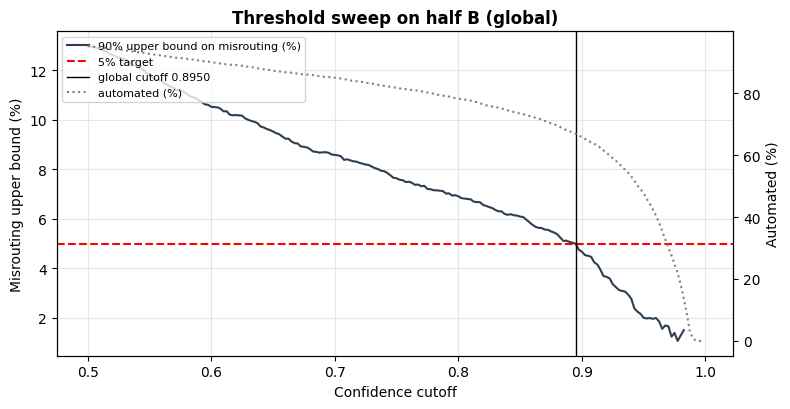

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

PROJ = '/content/drive/MyDrive/complaint_routing'
predB = Pcal[idxB].argmax(1); confB = Pcal[idxB].max(1); wrongB = predB != ycal[idxB]
pred_t = Pte.argmax(1); conf_t = Pte.max(1); wrong_t = pred_t != yte; N = len(yte)

t_global, _ = pick_rcps(confB, wrongB, min_n=MIN_N_GLOBAL)
t_ltt, _ = pick_ltt(confB, wrongB)
t_emp, _ = pick_empirical(confB, wrongB)
t_dept_uncorr = np.array([pick_rcps(confB[predB == k], wrongB[predB == k], min_n=MIN_N_DEPT)[0] for k in range(K)])
t_dept = np.array([pick_rcps(confB[predB == k], wrongB[predB == k], delta=DELTA / N_GRID, min_n=MIN_N_DEPT)[0] for k in range(K)])
t_dept_d8 = np.array([pick_rcps(confB[predB == k], wrongB[predB == k], delta=DELTA / K, min_n=MIN_N_DEPT)[0] for k in range(K)])
np.save(f'{PROJ}/t_dept.npy', t_dept); np.save(f'{PROJ}/t_global.npy', np.array([t_global]))

def evaluate(thr_vec):
    au = conf_t >= thr_vec
    return au.mean() * 100, (wrong_t[au].mean() * 100 if au.any() else np.nan)

T_lbl = f"<= {ALPHA*100:.0f}%"
rows = []
for name, thr_vec, scope in [
    ('Fixed cutoff 0.85', np.full(N, 0.85), 'none'),
    ('Empirical cutoff (no margin)', np.full(N, t_emp), 'none'),
    ('RCPS, global', np.full(N, t_global), 'overall ' + T_lbl),
    ('LTT, global (simplified, Bonferroni)', np.full(N, t_ltt), 'overall ' + T_lbl),
    ('RCPS, per-department (headline)', t_dept[pred_t], 'each department ' + T_lbl),
    ('RCPS, per-department, uncorrected (comparison only)', t_dept_uncorr[pred_t], 'each department ' + T_lbl),
    ('RCPS, per-department, delta/8 (across departments only)', t_dept_d8[pred_t], 'each department ' + T_lbl),
]:
    au, mi = evaluate(thr_vec)
    rows.append({'method': name, 'automated_%': round(au, 1),
                 'misrouted_among_automated_%': round(mi, 2) if np.isfinite(mi) else np.nan, 'guarantee': scope})
methods = pd.DataFrame(rows); methods.to_csv(f'{PROJ}/table_methods_main.csv', index=False)
print(methods.to_string(index=False))

drows = []
for k, lab in enumerate(LABELS):
    m = pred_t == k; a = m & (conf_t >= t_dept[k])
    drows.append({'department': lab,
                  'cutoff': round(float(t_dept[k]), 4) if np.isfinite(t_dept[k]) else 'defer all',
                  'test_n (predicted)': int(m.sum()), 'automated_%': round(a.sum() / max(m.sum(), 1) * 100, 1),
                  'misrouted_%': round(wrong_t[a].mean() * 100, 2) if a.any() else np.nan,
                  'meets_target': '-' if not a.any() else ('YES' if wrong_t[a].mean() <= ALPHA else 'NO')})
dtab = pd.DataFrame(drows); dtab.to_csv(f'{PROJ}/table_headline_dept.csv', index=False)
print("\nPer-department rule, headline"); print(dtab.to_string(index=False))

ub, au_curve = [], []
for t in GRID:
    m = confB >= t; n = int(m.sum())
    ub.append(cp_upper(int(wrongB[m].sum()), n, DELTA) * 100 if n >= MIN_N_GLOBAL else np.nan)
    au_curve.append(m.mean() * 100)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(GRID, ub, color='#2c3e50', label=f'{(1-DELTA)*100:.0f}% upper bound on misrouting (%)')
ax.axhline(ALPHA * 100, color='r', ls='--', label=f'{ALPHA*100:.0f}% target')
ax2 = ax.twinx(); ax2.plot(GRID, au_curve, color='gray', ls=':', label='automated (%)')
if np.isfinite(t_global):
    ax.axvline(t_global, color='k', lw=1, label=f'global cutoff {t_global:.4f}')
ax.set_xlabel('Confidence cutoff'); ax.set_ylabel('Misrouting upper bound (%)'); ax2.set_ylabel('Automated (%)')
ax.set_title('Threshold sweep on half B (global)', fontweight='bold')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{PROJ}/fig_threshold_sweep.png', dpi=160); plt.show()

In [ ]:
import numpy as np, pandas as pd

PROJ = '/content/drive/MyDrive/complaint_routing'
print("Global cutoff:", t_global, "| LTT cutoff:", t_ltt)
print("\nTarget comparison (headline rule at each target, same halves):")
cmp_rows = []
for a_t in [0.05, 0.07, 0.10]:
    td = np.array([pick_rcps(confB[predB == k], wrongB[predB == k], alpha=a_t, delta=DELTA / N_GRID, min_n=MIN_N_DEPT)[0]
                   for k in range(K)])
    au = conf_t >= td[pred_t]
    deferred = [LABELS[k] for k in range(K) if not np.isfinite(td[k])]
    cmp_rows.append({'target': f'{a_t*100:.0f}%',
                     'automated_%': round(au.mean() * 100, 1),
                     'misrouted_among_automated_%': round(wrong_t[au].mean() * 100, 2) if au.any() else np.nan,
                     'misrouted_overall_%': round((wrong_t & au).sum() / N * 100, 2),
                     'deferred_in_full': ', '.join(deferred) if deferred else 'none'})
cmp = pd.DataFrame(cmp_rows); cmp.to_csv(f'{PROJ}/table_target_comparison.csv', index=False)
print(cmp.to_string(index=False))

Global cutoff: 0.895 | LTT cutoff: 0.9125

Target comparison (headline rule at each target, same halves):
target  automated_%  misrouted_among_automated_%  misrouted_overall_%                                                    deferred_in_full
    5%         34.5                         2.54                 0.88 Credit Card, Debt Collection, Money Transfer, Vehicle/Personal Loan
    7%         43.6                         4.17                 1.82                 Credit Card, Debt Collection, Vehicle/Personal Loan
   10%         66.5                         5.78                 3.84                                                                none


## 7. Robustness: 20 different calibration splits
For each of 20 random splits, the four parts are rebuilt (the test set stays fixed). We refit the temperature, the cutoffs and the rule, then evaluate on the test set.

Two rates are reported. "Violation" means the misrouting among automated complaints is above 5%. The target is that at most 10% of repeats violate it.

In [ ]:
import numpy as np, pandas as pd
from scipy.optimize import minimize_scalar
from sklearn.model_selection import train_test_split

PROJ = '/content/drive/MyDrive/complaint_routing'
R = 20
glob_rows, dept_overall, dept_rows = [], [], []
for r in range(R):
    iA, iB_r = train_test_split(np.arange(len(ycal)), test_size=0.5, stratify=ycal, random_state=100 + r)
    iA1, iA2 = train_test_split(iA, test_size=0.5, stratify=ycal[iA], random_state=200 + r)
    Tr = minimize_scalar(lambda t: nll(t, Lcal[iA1], ycal[iA1]), bounds=(0.5, 5.0), method='bounded').x
    Pc = softmax(Lcal[iB_r] / Tr); Pt = softmax(Lte / Tr)
    cB, pB, yB = Pc.max(1), Pc.argmax(1), ycal[iB_r]; wB = pB != yB
    cT, pT = Pt.max(1), Pt.argmax(1); wT = pT != yte

    tg, _ = pick_rcps(cB, wB, min_n=MIN_N_GLOBAL)
    au = cT >= tg
    mi = wT[au].mean() * 100 if au.any() else np.nan
    glob_rows.append({'repeat': r, 'auto': au.mean() * 100, 'misroute': mi,
                      'violated': bool(au.any() and mi > ALPHA * 100)})

    td = np.array([pick_rcps(cB[pB == k], wB[pB == k], delta=DELTA / N_GRID, min_n=MIN_N_DEPT)[0] for k in range(K)])
    au = cT >= td[pT]
    mi = wT[au].mean() * 100 if au.any() else np.nan
    dept_overall.append({'repeat': r, 'auto': au.mean() * 100, 'misroute': mi,
                         'departments_deferred': int(np.sum(~np.isfinite(td)))})
    for k in range(K):
        a = au & (pT == k)
        if not a.any(): continue
        mk = wT[a].mean() * 100
        dept_rows.append({'repeat': r, 'dept': LABELS[k], 'misroute': mk, 'violated': bool(mk > ALPHA * 100)})

G = pd.DataFrame(glob_rows); D = pd.DataFrame(dept_rows); O = pd.DataFrame(dept_overall)

def ci(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return f"{x.mean():.2f}  [{np.percentile(x, 2.5):.2f}, {np.percentile(x, 97.5):.2f}]"

summary = pd.DataFrame([
    {'method': 'RCPS global',
     'automated_% mean [95% interval]': ci(G['auto']),
     'overall misrouted_% mean [95% interval]': ci(G['misroute']),
     'violation rate (target <= 10%)': f"{G['violated'].mean()*100:.1f}% of repeats"},
    {'method': 'RCPS per-department',
     'automated_% mean [95% interval]': ci(O['auto']),
     'overall misrouted_% mean [95% interval]': ci(O['misroute']),
     'violation rate (target <= 10%)': f"{D['violated'].mean()*100:.1f}% of (repeat, department) pairs, from {len(D)} pairs"},
])
summary.to_csv(f'{PROJ}/table_robustness.csv', index=False)
print(summary.to_string(index=False))
print("Average number of departments deferred in full per split:", round(O['departments_deferred'].mean(), 2))

             method automated_% mean [95% interval] overall misrouted_% mean [95% interval]                    violation rate (target <= 10%)
        RCPS global           65.62  [61.83, 69.51]                      4.48  [3.98, 5.01]                                   5.0% of repeats
RCPS per-department           25.03  [15.77, 36.62]                      2.84  [1.75, 3.66] 0.0% of (repeat, department) pairs, from 58 pairs
Average number of departments deferred in full per split: 5.1


## 8. Hybrid score: ranking ablations
The fused score combines five signals from both models: the calibrated top-1 probability, the margin between the top two departments, the entropy, whether the two models agree, and the SVM's support for DistilBERT's choice. A logistic regression is fitted on half A2 to predict whether DistilBERT is correct.

The fused score is used only for ranking. The cutoffs in Section 6 use DistilBERT's calibrated confidence, so the fused score does not change any routing decision.

Area under the risk-coverage curve (AURC) is the average error among the most confident complaints, across all coverage levels. Lower is better.

Standardised coefficients (signs are meaningful; sizes are not, because top-1 and margin are correlated):
  top-1 probability    -0.364
  margin               +0.534
  entropy              -0.672
  models agree         -0.124
  SVM support          +0.681
                                             scoring  AURC (lower is better)  risk at 60% coverage %  risk at 80% coverage %
                          DistilBERT confidence only                  0.0408                    3.82                    7.07
                                 SVM confidence only                  0.0502                    5.02                    8.37
                       Average of both probabilities                  0.0390                    3.84                    6.74
Fusion without SVM features (top-1, margin, entropy)                  0.0408                    3.80                    7.07
                        Full fused score (5 signals)                  0.0382                    3.54                   

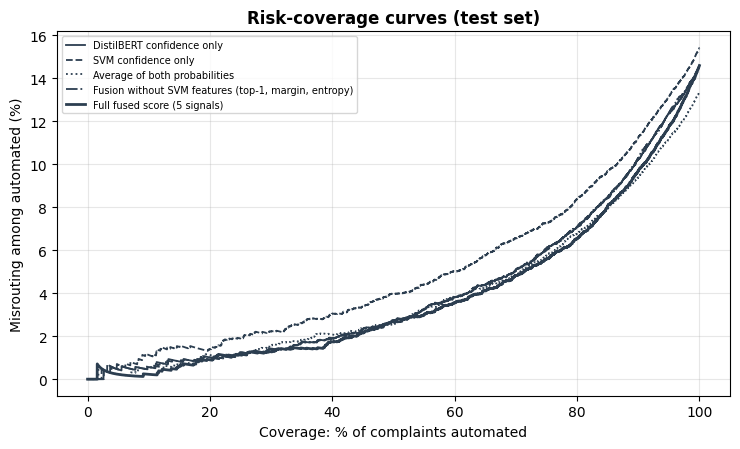

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

PROJ = '/content/drive/MyDrive/complaint_routing'
Xc, pbc = feats(Pcal, Scal); Xt, pbt = feats(Pte, Ste)
corr_c = (pbc == ycal).astype(int)
wrong_plain = pbt != yte

sc = StandardScaler().fit(Xc[idxA1])
fuser = LogisticRegression(max_iter=2000, C=1.0).fit(sc.transform(Xc[idxA1]), corr_c[idxA1])
fused = fuser.predict_proba(sc.transform(Xt))[:, 1]
names = ['top-1 probability', 'margin', 'entropy', 'models agree', 'SVM support']
print("Standardised coefficients (signs are meaningful; sizes are not, because top-1 and margin are correlated):")
for n, w in zip(names, fuser.coef_[0]): print(f"  {n:<20} {w:+.3f}")

sc3 = StandardScaler().fit(Xc[idxA1][:, :3])
f3 = LogisticRegression(max_iter=2000).fit(sc3.transform(Xc[idxA1][:, :3]), corr_c[idxA1])
no_svm = f3.predict_proba(sc3.transform(Xt[:, :3]))[:, 1]
Pavg = (Pte + Ste) / 2

cands = {
    'DistilBERT confidence only': (Pte.max(1), pbt),
    'SVM confidence only': (Ste.max(1), Ste.argmax(1)),
    'Average of both probabilities': (Pavg.max(1), Pavg.argmax(1)),
    'Fusion without SVM features (top-1, margin, entropy)': (no_svm, pbt),
    'Full fused score (5 signals)': (fused, pbt),
}
rows, curves = [], {}
for name, (score, pr) in cands.items():
    w = pr != yte
    rc = risk_curve(score, w); curves[name] = rc
    rows.append({'scoring': name, 'AURC (lower is better)': round(rc.mean(), 4),
                 'risk at 60% coverage %': round(rc[int(0.6 * N) - 1] * 100, 2),
                 'risk at 80% coverage %': round(rc[int(0.8 * N) - 1] * 100, 2)})
abl = pd.DataFrame(rows); abl.to_csv(f'{PROJ}/table_ablation.csv', index=False)
print(abl.to_string(index=False))

rng = np.random.default_rng(0)
base_aurc = aurc(fused, wrong_plain)
perm = {n: [] for n in names}
for j, n in enumerate(names):
    for _ in range(20):
        Xp = Xt.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        s = fuser.predict_proba(sc.transform(Xp))[:, 1]
        perm[n].append(aurc(s, wrong_plain) - base_aurc)
perm_tab = pd.DataFrame([{'feature': n, 'AURC increase when shuffled (mean)': round(np.mean(perm[n]), 4),
                          '± sd over 20 shuffles': round(np.std(perm[n]), 4)} for n in names])
perm_tab.to_csv(f'{PROJ}/table_permutation.csv', index=False)
print("\nPermutation importance (bigger AURC increase = more important):")
print(perm_tab.to_string(index=False))

def boot_diff(a_score, b_score, reps=1000):
    out = []
    for _ in range(reps):
        i = rng.integers(0, N, N)
        out.append(aurc(a_score[i], wrong_plain[i]) - aurc(b_score[i], wrong_plain[i]))
    out = np.array(out)
    return round(float(np.mean(out)), 4), round(float(np.percentile(out, 2.5)), 4), round(float(np.percentile(out, 97.5)), 4)

sig = []
for label, other in [('DistilBERT confidence only', Pte.max(1)), ('Average of both probabilities', Pavg.max(1))]:
    m_, lo, hi = boot_diff(fused, other)
    sig.append({'comparison': f'fused minus {label}', 'AURC difference': m_, '95% interval': f'[{lo}, {hi}]',
                'significant at 5%?': 'yes' if (hi < 0 or lo > 0) else 'no'})
sig_tab = pd.DataFrame(sig); sig_tab.to_csv(f'{PROJ}/table_significance.csv', index=False)
print("\nPaired bootstrap (1000 resamples of the test set):"); print(sig_tab.to_string(index=False))

styles = ['-', '--', ':', '-.', '-']
plt.figure(figsize=(7.5, 4.6))
for (name, rc), ls in zip(curves.items(), styles):
    cov = np.arange(1, N + 1) / N
    plt.plot(cov * 100, rc * 100, ls=ls, lw=2 if 'Full' in name else 1.3, label=name, color='#2c3e50')
plt.xlabel('Coverage: % of complaints automated'); plt.ylabel('Misrouting among automated (%)')
plt.title('Risk-coverage curves (test set)', fontweight='bold')
plt.legend(fontsize=7); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f'{PROJ}/fig_risk_coverage.png', dpi=160); plt.show()

## 9. Diagnostics: per-class results, confusions, and calibration
These results are for DistilBERT on the test set. The reliability diagram compares DistilBERT before and after scaling, and the fused score.

                       precision  recall  f1-score   support
Bank Account               0.838   0.839     0.839  1200.000
Credit Card                0.820   0.855     0.837  1200.000
Credit Reporting           0.848   0.807     0.827  1200.000
Debt Collection            0.799   0.793     0.796  1200.000
Money Transfer             0.854   0.808     0.830   506.000
Mortgage                   0.933   0.932     0.933  1200.000
Student Loan               0.920   0.940     0.930  1200.000
Vehicle/Personal Loan      0.821   0.832     0.826  1200.000
accuracy                   0.854   0.854     0.854     0.854
macro avg                  0.854   0.851     0.852  8906.000
weighted avg               0.854   0.854     0.854  8906.000


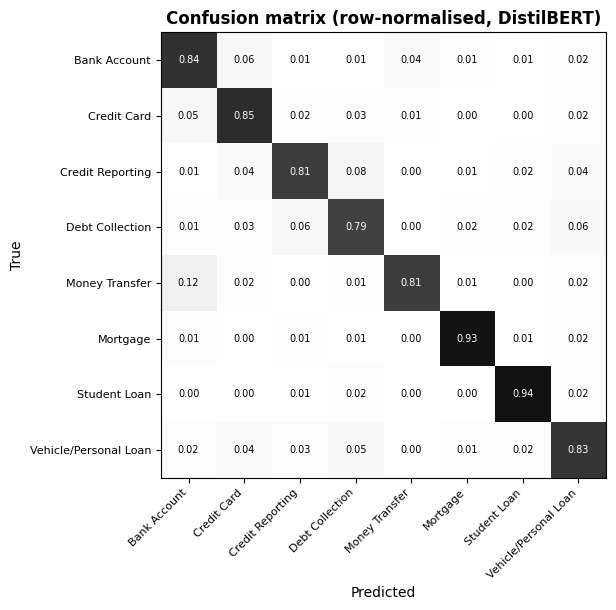

 count       true department  predicted department
    94      Credit Reporting       Debt Collection
    77          Bank Account           Credit Card
    69       Debt Collection Vehicle/Personal Loan
    68       Debt Collection      Credit Reporting
    65           Credit Card          Bank Account
    62        Money Transfer          Bank Account
    55 Vehicle/Personal Loan       Debt Collection
    49      Credit Reporting           Credit Card
    44 Vehicle/Personal Loan           Credit Card
    44      Credit Reporting Vehicle/Personal Loan


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

PROJ = '/content/drive/MyDrive/complaint_routing'
rep = pd.DataFrame(classification_report(yte, pred_t, target_names=LABELS, output_dict=True)).T.round(3)
rep.to_csv(f'{PROJ}/table_distilbert_per_class.csv'); print(rep)

cm = confusion_matrix(yte, pred_t, normalize='true')
fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.imshow(cm, cmap='Greys', vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_yticks(range(K))
ax.set_xticklabels(LABELS, rotation=45, ha='right', fontsize=8); ax.set_yticklabels(LABELS, fontsize=8)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha='center', va='center', fontsize=7,
                color='white' if cm[i, j] > .5 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Confusion matrix (row-normalised, DistilBERT)', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{PROJ}/fig_confusion.png', dpi=160); plt.show()

cnt_m = confusion_matrix(yte, pred_t); np.fill_diagonal(cnt_m, 0)
pairs = sorted([(int(cnt_m[i, j]), LABELS[i], LABELS[j]) for i in range(K) for j in range(K) if cnt_m[i, j] > 0], reverse=True)[:10]
top = pd.DataFrame(pairs, columns=['count', 'true department', 'predicted department'])
top.to_csv(f'{PROJ}/table_top_confusions.csv', index=False); print(top.to_string(index=False))

Calibration on the test set (bootstrap intervals from 200 resamples):
 bins  ECE calibrated DistilBERT 95% interval (calibrated)  ECE fused score 95% interval (fused)
   10                     0.0136          [0.0092, 0.0206]           0.0084     [0.0067, 0.0169]
   15                     0.0131          [0.0108, 0.0212]           0.0150     [0.0118, 0.0219]
   20                     0.0168          [0.0129, 0.0244]           0.0191     [0.0159, 0.0267]


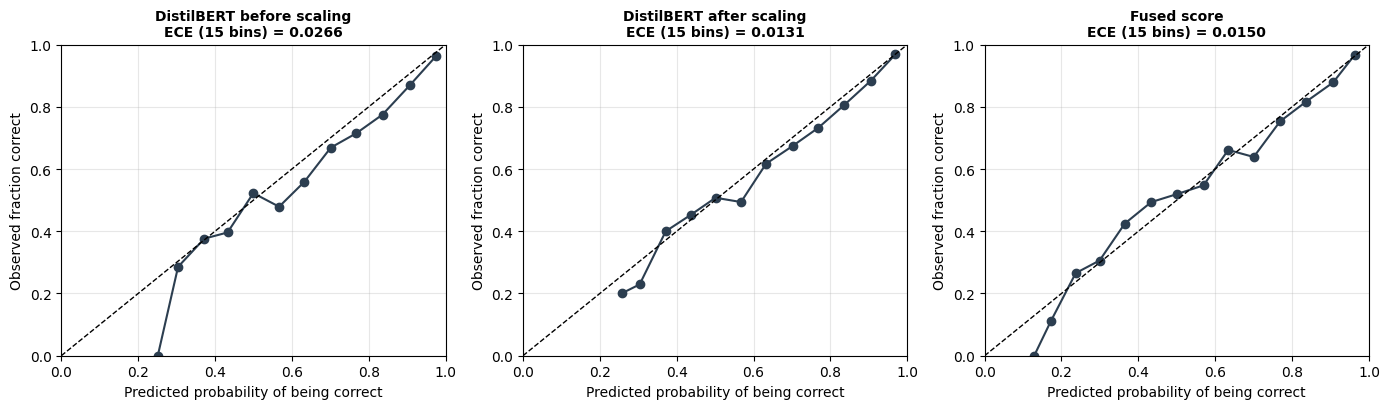

Macro one-vs-rest ROC-AUC: DistilBERT 0.9803   SVM 0.9765


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import softmax as sp_softmax
from sklearn.metrics import roc_auc_score

PROJ = '/content/drive/MyDrive/complaint_routing'
N_BOOT = 200
rng = np.random.default_rng(1)
correct_t = (pred_t == yte).astype(float)
conf_cal_t = Pte.max(1)
ece_rows = []
for bins in [10, 15, 20]:
    e_c = ece(conf_cal_t, correct_t, bins); e_f = ece(fused, correct_t, bins)
    bc, bf = [], []
    for _ in range(N_BOOT):
        i = rng.integers(0, N, N)
        bc.append(ece(conf_cal_t[i], correct_t[i], bins)); bf.append(ece(fused[i], correct_t[i], bins))
    ece_rows.append({'bins': bins,
                     'ECE calibrated DistilBERT': round(e_c, 4),
                     '95% interval (calibrated)': f"[{np.percentile(bc, 2.5):.4f}, {np.percentile(bc, 97.5):.4f}]",
                     'ECE fused score': round(e_f, 4),
                     '95% interval (fused)': f"[{np.percentile(bf, 2.5):.4f}, {np.percentile(bf, 97.5):.4f}]"})
ece_tab = pd.DataFrame(ece_rows); ece_tab.to_csv(f'{PROJ}/table_ece_bins.csv', index=False)
print("Calibration on the test set (bootstrap intervals from 200 resamples):")
print(ece_tab.to_string(index=False))

Praw_te = sp_softmax(Lte, axis=1)
xr, yr, e_raw = None, None, ece(Praw_te.max(1), correct_t, 15)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
panels = [('DistilBERT before scaling', Praw_te.max(1)), ('DistilBERT after scaling', conf_cal_t), ('Fused score', fused)]
for a, (title, s) in zip(ax, panels):
    edges = np.linspace(0, 1, 16); xs, ys = [], []
    for i in range(15):
        m = (s > edges[i]) & (s <= edges[i + 1])
        if m.sum(): xs.append(s[m].mean()); ys.append(correct_t[m].mean())
    a.plot(xs, ys, 'o-', color='#2c3e50'); a.plot([0, 1], [0, 1], 'k--', lw=1)
    a.set_title(f'{title}\nECE (15 bins) = {ece(s, correct_t, 15):.4f}', fontsize=10, fontweight='bold')
    a.set_xlabel('Predicted probability of being correct'); a.set_ylabel('Observed fraction correct')
    a.set_xlim(0, 1); a.set_ylim(0, 1); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{PROJ}/fig_reliability.png', dpi=160); plt.show()

auc_d = roc_auc_score(yte, Pte, multi_class='ovr', average='macro')
auc_s = roc_auc_score(yte, Ste, multi_class='ovr', average='macro')
print(f"Macro one-vs-rest ROC-AUC: DistilBERT {auc_d:.4f}   SVM {auc_s:.4f}")

## 10. Headline result at the 5% target
Per-department rule on the balanced test set. Complaints the rule defers go to a human reviewer.

Debt Collection, Credit Card, Money Transfer or Vehicle/Personal Loan may be deferred in full. A department is deferred when no cutoff on the grid satisfies the corrected bound on half B. The guarantee holds per predicted department, on this test set, if the data are exchangeable with the calibration data.

Headline: automated 34.5%  |  misrouted among automated 2.54%  |  overall misrouted 0.88%


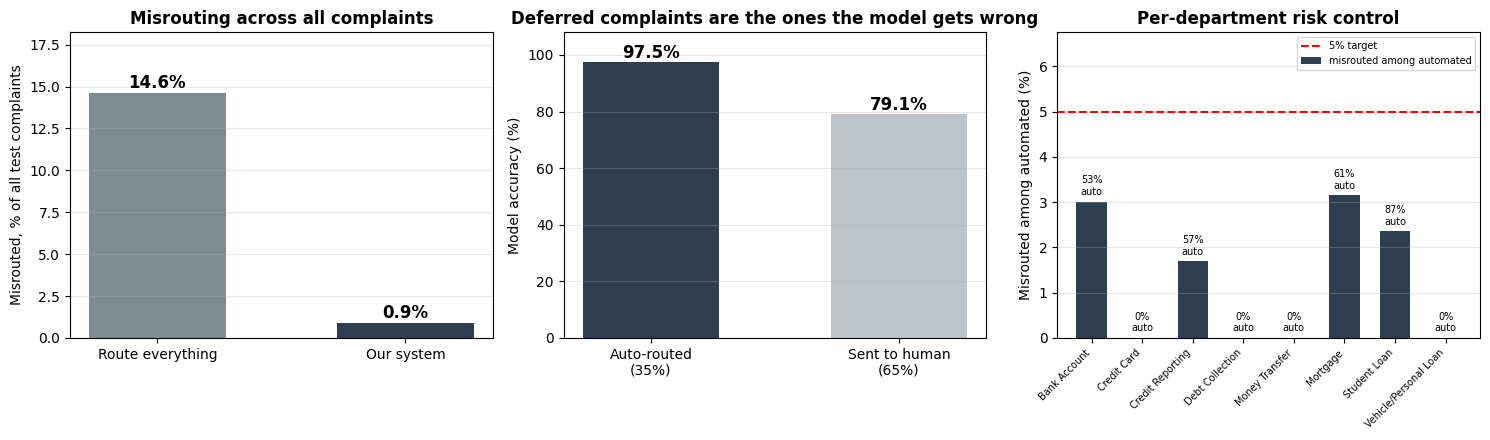

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

PROJ = '/content/drive/MyDrive/complaint_routing'
auto = conf_t >= t_dept[pred_t]
n_auto = int(auto.sum()); mis_auto = int((wrong_t & auto).sum())
print(f"Headline: automated {n_auto/N*100:.1f}%  |  misrouted among automated {mis_auto/n_auto*100:.2f}%"
      f"  |  overall misrouted {mis_auto/N*100:.2f}%")

dep_auto, dep_mis = [], []
for k in range(K):
    m = pred_t == k; a = m & auto
    dep_auto.append(a.sum() / max(m.sum(), 1) * 100)
    dep_mis.append(wrong_t[a].mean() * 100 if a.any() else 0.0)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
full_mis = wrong_t.mean() * 100; sys_overall = mis_auto / N * 100
ax[0].bar(['Route everything', 'Our system'], [full_mis, sys_overall], color=['#7f8c8d', '#2c3e50'], width=.55)
for i, v in enumerate([full_mis, sys_overall]):
    ax[0].text(i, v + .3, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=12)
ax[0].set_ylabel('Misrouted, % of all test complaints'); ax[0].set_ylim(0, max(full_mis, 1) * 1.25)
ax[0].set_title('Misrouting across all complaints', fontweight='bold'); ax[0].grid(axis='y', alpha=.3)

acc_auto = (~wrong_t[auto]).mean() * 100; acc_def = (~wrong_t[~auto]).mean() * 100 if (~auto).any() else np.nan
ax[1].bar([f'Auto-routed\n({n_auto/N*100:.0f}%)', f'Sent to human\n({100-n_auto/N*100:.0f}%)'], [acc_auto, acc_def],
          color=['#2c3e50', '#bdc3c7'], width=.55)
for i, v in enumerate([acc_auto, acc_def]):
    if np.isfinite(v): ax[1].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=12)
ax[1].set_ylabel('Model accuracy (%)'); ax[1].set_ylim(0, 108)
ax[1].set_title('Deferred complaints are the ones the model gets wrong', fontweight='bold'); ax[1].grid(axis='y', alpha=.3)

x = np.arange(K)
ax[2].bar(x, dep_mis, color='#2c3e50', width=.6, label='misrouted among automated')
ax[2].axhline(ALPHA * 100, color='r', ls='--', lw=1.5, label=f'{ALPHA*100:.0f}% target')
for i, a_ in enumerate(dep_auto):
    ax[2].text(i, dep_mis[i] + .15, f'{a_:.0f}%\nauto', ha='center', fontsize=7)
ax[2].set_xticks(x); ax[2].set_xticklabels(LABELS, rotation=45, ha='right', fontsize=7)
ax[2].set_ylabel('Misrouted among automated (%)'); ax[2].set_ylim(0, max(max(dep_mis), ALPHA * 100) * 1.35)
ax[2].set_title('Per-department risk control', fontweight='bold'); ax[2].legend(fontsize=7); ax[2].grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(f'{PROJ}/fig0_headline.png', dpi=170); plt.show()

pd.DataFrame([{'automated_%': round(n_auto / N * 100, 2),
               'misrouted_among_automated_%': round(mis_auto / n_auto * 100, 2),
               'misrouted_overall_%': round(mis_auto / N * 100, 2)}]).to_csv(f'{PROJ}/table_headline.csv', index=False)

## 11. Review budget, reviewer accuracy and cost
A review budget is an operator choice, not a statistical target. The lowest-confidence fraction of complaints is sent to a reviewer. It gives no bound, so it is a baseline.

Reviewers are not perfect. End-to-end accuracy assumes the reviewer is right with accuracy r. The break-even reviewer accuracy is the value of r at which routing with review is no better than full automation.

Cost model: 1 unit per complaint sent to review, and c units per misrouted automated complaint. Full automation has no reviews. The results are for c = 5, 10 and 20.

In [ ]:
import numpy as np, pandas as pd

PROJ = '/content/drive/MyDrive/complaint_routing'
N = len(yte)
acc_full = 1 - wrong_t.mean()

def breakeven(auto_mask):
    n_def = int((~auto_mask).sum()); corr_auto = int((~wrong_t & auto_mask).sum())
    return (acc_full * N - corr_auto) / n_def if n_def else np.nan

def summarise(auto_mask, label):
    n_a = int(auto_mask.sum()); n_d = N - n_a
    mis_a = int((wrong_t & auto_mask).sum()); corr_a = int((~wrong_t & auto_mask).sum())
    return {'rule': label, 'automated_%': round(n_a / N * 100, 1),
            'misrouted_among_automated_%': round(mis_a / n_a * 100, 2) if n_a else np.nan,
            'end_to_end_acc_perfect_reviewer_%': round((corr_a + n_d) / N * 100, 2),
            'end_to_end_acc_reviewer_60_%': round((corr_a + 0.60 * n_d) / N * 100, 2),
            'break_even_reviewer_%': round(breakeven(auto_mask) * 100, 2) if n_d else np.nan,
            'cost_c5': n_d + 5 * mis_a, 'cost_c10': n_d + 10 * mis_a, 'cost_c20': n_d + 20 * mis_a}

auto_head = conf_t >= t_dept[pred_t]
rows = [summarise(auto_head, 'Per-department rule (headline)')]
order = np.argsort(conf_t, kind='stable')          # lowest confidence first
budget_rows = []
for b in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    a = np.ones(N, bool); a[order[: int(round(b * N))]] = False
    rows.append(summarise(a, f'Review budget {b*100:.0f}% (no bound)'))
bud = pd.DataFrame(rows); bud.to_csv(f'{PROJ}/table_budget_and_cost.csv', index=False)
print(bud.to_string(index=False))

print("\nReviewer accuracy sweep at a 30% review budget:")
a30 = np.ones(N, bool); a30[order[: int(round(0.3 * N))]] = False
n_a30 = int(a30.sum()); corr_a30 = int((~wrong_t & a30).sum()); n_d30 = N - n_a30
sweep = pd.DataFrame([{'reviewer accuracy %': round(r * 100, 1),
                       'end-to-end accuracy %': round((corr_a30 + r * n_d30) / N * 100, 2)}
                      for r in [1.0, 0.9, 0.85, 0.75, 0.6]])
sweep.to_csv(f'{PROJ}/table_reviewer_sweep.csv', index=False); print(sweep.to_string(index=False))
print(f"Break-even reviewer accuracy at 30% budget: {breakeven(a30)*100:.2f}%")
print(f"Full automation accuracy: {acc_full*100:.2f}%")

print("\nCost-optimal review budget by cost ratio (grid of 5% steps):")
best_rows = []
for c in [5, 10, 20]:
    costs = []
    for b in np.arange(0, 0.501, 0.05):
        a = np.ones(N, bool); a[order[: int(round(b * N))]] = False
        costs.append((int(N - a.sum()) + c * int((wrong_t & a).sum()), round(b * 100)))
    best = min(costs)
    best_rows.append({'c': c, 'best budget %': best[1], 'cost at best': best[0]})
print(pd.DataFrame(best_rows).to_string(index=False))

                          rule  automated_%  misrouted_among_automated_%  end_to_end_acc_perfect_reviewer_%  end_to_end_acc_reviewer_60_%  break_even_reviewer_%  cost_c5  cost_c10  cost_c20
Per-department rule (headline)         34.5                         2.54                              99.12                         72.94                  79.06     6221      6611      7391
   Review budget 0% (no bound)        100.0                        14.59                              85.41                         85.41                    NaN     6495     12990     25980
  Review budget 10% (no bound)         90.0                        10.21                              90.82                         86.81                  46.02     4981      9071     17251
  Review budget 20% (no bound)         80.0                         7.07                              94.34                         86.34                  55.36     4301      6821     11861
  Review budget 30% (no bound)         70.0       

## 12. Conformal risk control baseline
Conformal risk control (Angelopoulos et al.) picks one confidence cutoff for all departments, with a finite-sample guarantee. Its loss counts a misrouted automated complaint. We use half B, the same data as the cutoffs above.

Important: this guarantee is on the overall misrouting rate (over all complaints), not on the misrouting among automated complaints. The results should be compared with the overall column of the headline (0.89% at the 5% target), not with the 5% per-department target.

In [ ]:
import numpy as np, pandas as pd

PROJ = '/content/drive/MyDrive/complaint_routing'
confB_c = Pcal[idxB].max(1); wrongB_c = Pcal[idxB].argmax(1) != ycal[idxB]
nB = len(idxB)

def crc_cutoff(alpha):
    feasible = []
    for lam in GRID:
        R_hat = np.mean((confB_c >= lam) & wrongB_c)           # overall misrouting if cutoff is lam
        if (nB / (nB + 1)) * R_hat + 1 / (nB + 1) <= alpha:
            feasible.append(lam)
    return min(feasible) if feasible else None

rows = []
for a_t in [0.01, 0.02, 0.05]:
    lam = crc_cutoff(a_t)
    if lam is None:
        rows.append({'target (overall misrouting)': f'{a_t*100:.0f}%', 'cutoff': 'none on grid',
                     'automated_%': 0.0, 'misrouted_overall_%': np.nan, 'misrouted_among_automated_%': np.nan})
        continue
    au = conf_t >= lam
    rows.append({'target (overall misrouting)': f'{a_t*100:.0f}%', 'cutoff': round(float(lam), 4),
                 'automated_%': round(au.mean() * 100, 1),
                 'misrouted_overall_%': round((wrong_t & au).sum() / N * 100, 2),
                 'misrouted_among_automated_%': round(wrong_t[au].mean() * 100, 2) if au.any() else np.nan})
crc = pd.DataFrame(rows); crc.to_csv(f'{PROJ}/table_crc.csv', index=False)
print(crc.to_string(index=False))
print("\nLearn-then-test (simplified, global) is in Section 6 for comparison.")

target (overall misrouting)  cutoff  automated_%  misrouted_overall_%  misrouted_among_automated_%
                         1%  0.9450         49.2                 1.29                         2.62
                         2%  0.9175         59.4                 2.23                         3.76
                         5%  0.8000         76.7                 4.83                         6.30

Learn-then-test (simplified, global) is in Section 6 for comparison.


## 13. Natural class mix
The balanced test set does not reflect the class mix a deployed system would see. The natural pool holds the complaints that the cap removed. These were never used in training, calibration or test.

Money Transfer has no complaints in the pool, because the cap removed none of them. The model still predicts Money Transfer for some pool complaints. Those predictions are dropped from the pool results, and the count is printed. They have no true label to be checked against.

First, the frozen system: the cutoffs from Section 6, unchanged. Second, the same rule recalibrated on half of the pool and tested on the other half (Section 14).

Reusing pool_logits.npy
Pool size: 132064 | dropped (predicted Money Transfer): 631 | used: 131433
DistilBERT accuracy on the used pool: 84.89%
Frozen system: automated 35.2%  |  misrouted among automated 2.88%  |  overall misrouted 1.01%
           department  pool_n (true label)  automated_%  misrouted_among_automated_% meets_target
         Bank Account                 7273         50.7                         3.71          YES
          Credit Card                14444          0.0                          NaN            -
     Credit Reporting                41320         62.0                         0.88          YES
      Debt Collection                35982          0.0                          NaN            -
       Money Transfer                    0          0.0                          NaN            -
             Mortgage                24386         62.5                         1.78          YES
         Student Loan                 4205         72.3                    

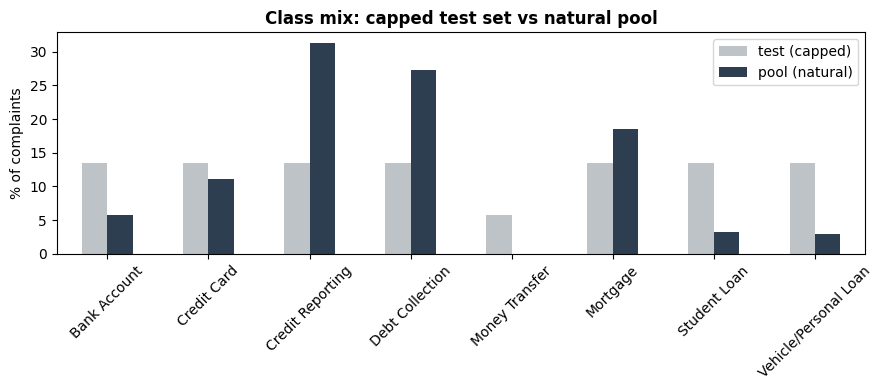

In [ ]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt

PROJ = '/content/drive/MyDrive/complaint_routing'
pool = pd.read_csv(f'{PROJ}/pool.csv'); ypool_all = pool['label'].map(L2I).values
pool_path = f'{PROJ}/pool_logits.npy'
if os.path.exists(pool_path) and not RECOMPUTE_POOL_LOGITS:
    Lpool = np.load(pool_path); print("Reusing pool_logits.npy")
else:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok_p = AutoTokenizer.from_pretrained(f'{PROJ}/model')
    model_p = AutoModelForSequenceClassification.from_pretrained(f'{PROJ}/model').to('cuda').eval()
    texts = pool['text'].tolist(); out = []
    with torch.no_grad():
        for i in range(0, len(texts), 128):
            e = tok_p(texts[i:i+128], truncation=True, max_length=192, padding='max_length', return_tensors='pt').to('cuda')
            with torch.amp.autocast('cuda'):
                out.append(model_p(**e).logits.float().cpu().numpy())
    Lpool = np.concatenate(out); np.save(pool_path, Lpool)
    del model_p; torch.cuda.empty_cache()

Pp = softmax(Lpool / T); pred_all = Pp.argmax(1); conf_all = Pp.max(1)
MT = L2I['Money Transfer']
keep = pred_all != MT
print(f"Pool size: {len(pool)} | dropped (predicted Money Transfer): {int((~keep).sum())} | used: {int(keep.sum())}")
pred_p = pred_all[keep]; conf_p = conf_all[keep]; yp = ypool_all[keep]; wrong_p = pred_p != yp
auto_p = conf_p >= t_dept[pred_p]
print(f"DistilBERT accuracy on the used pool: {(~wrong_p).mean()*100:.2f}%")
print(f"Frozen system: automated {auto_p.mean()*100:.1f}%  |  misrouted among automated {wrong_p[auto_p].mean()*100:.2f}%"
      f"  |  overall misrouted {(wrong_p & auto_p).sum()/len(yp)*100:.2f}%")

rows = []
for k, lab in enumerate(LABELS):
    m = pred_p == k; a = m & auto_p
    rows.append({'department': lab, 'pool_n (true label)': int((yp == k).sum()),
                 'automated_%': round(a.sum() / max(m.sum(), 1) * 100, 1),
                 'misrouted_among_automated_%': round(wrong_p[a].mean() * 100, 2) if a.any() else np.nan,
                 'meets_target': '-' if not a.any() else ('YES' if wrong_p[a].mean() <= ALPHA else 'NO')})
ptab = pd.DataFrame(rows); ptab.to_csv(f'{PROJ}/table_pool_frozen.csv', index=False); print(ptab.to_string(index=False))

mix = pd.DataFrame({'test (capped)': np.bincount(yte, minlength=K) / len(yte) * 100,
                    'pool (natural)': np.bincount(ypool_all, minlength=K) / len(ypool_all) * 100}, index=LABELS)
ax = mix.plot.bar(figsize=(9, 4), color=['#bdc3c7', '#2c3e50'], rot=45)
ax.set_ylabel('% of complaints'); ax.set_title('Class mix: capped test set vs natural pool', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{PROJ}/fig_pool_mix.png', dpi=160); plt.show()

## 14. Natural class mix, recalibrated
Half of the pool (A) picks the per-department cutoffs with the same rule as Section 6, using the corrected bound. The other half (B) is never used for choosing, and it gives the result.

In [ ]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

PROJ = '/content/drive/MyDrive/complaint_routing'
iA_p, iB_p = train_test_split(np.arange(len(yp)), test_size=0.5, stratify=yp, random_state=42)

t_pool = np.array([pick_rcps(conf_p[iA_p][pred_p[iA_p] == k], wrong_p[iA_p][pred_p[iA_p] == k],
                             delta=DELTA / N_GRID, min_n=MIN_N_DEPT)[0] for k in range(K)])
pB, wB = pred_p[iB_p], wrong_p[iB_p]
au = conf_p[iB_p] >= t_pool[pB]
print(f"Recalibrated natural mix (half B, n={len(iB_p)}): automated {au.mean()*100:.1f}%"
      f"  |  misrouted among automated {wB[au].mean()*100:.2f}%  |  overall {(wB & au).sum()/len(iB_p)*100:.2f}%")

rows = []
for k, lab in enumerate(LABELS):
    m = pB == k; a = m & au
    rows.append({'department': lab,
                 'cutoff': round(float(t_pool[k]), 4) if np.isfinite(t_pool[k]) else 'defer all',
                 'n': int(m.sum()), 'automated_%': round(a.sum() / max(m.sum(), 1) * 100, 1),
                 'misrouted_among_automated_%': round(wB[a].mean() * 100, 2) if a.any() else np.nan,
                 'meets_target': '-' if not a.any() else ('YES' if wB[a].mean() <= ALPHA else 'NO')})
tab = pd.DataFrame(rows); tab.to_csv(f'{PROJ}/table_natural_recalibrated.csv', index=False)
print(tab.to_string(index=False))

Recalibrated natural mix (half B, n=65717): automated 63.1%  |  misrouted among automated 4.21%  |  overall 2.65%
           department    cutoff     n  automated_%  misrouted_among_automated_% meets_target
         Bank Account    0.9475  3985         48.2                         3.33          YES
          Credit Card    0.9325  7966         37.2                         4.59          YES
     Credit Reporting      0.58 18198         91.2                         4.61          YES
      Debt Collection       0.9 16353         51.4                         3.98          YES
       Money Transfer defer all     0          0.0                          NaN            -
             Mortgage    0.7675 12294         90.6                         3.93          YES
         Student Loan    0.9875  2958         14.1                         1.20          YES
Vehicle/Personal Loan defer all  3963          0.0                          NaN            -


## 15. Later complaints (temporal check)
The random split assumes that complaints from different dates look alike. This check tests that assumption, without retraining. The frozen cutoffs from Section 6 are applied to the pool complaints, split by received date: the earliest 85% and the latest 15%.

This is a weaker test than retraining on older data and testing on newer data. The model was trained on a random split, so the check only asks whether the cutoffs still hold for later complaints.

In [ ]:
import re, numpy as np, pandas as pd

PROJ = '/content/drive/MyDrive/complaint_routing'
raw_t = df[['Date received', 'Product', 'Consumer Complaint']].dropna(subset=['Product', 'Consumer Complaint']).copy()
raw_t['label'] = raw_t['Product'].map(DEPT)
raw_t = raw_t.dropna(subset=['label'])
raw_t['text'] = raw_t['Consumer Complaint'].map(clean)
raw_t = raw_t[raw_t['text'].str.split().str.len() >= 20]
date_map = raw_t.drop_duplicates('text').set_index('text')['Date received']

pool_t = pd.read_csv(f'{PROJ}/pool.csv')
pool_t['date'] = pd.to_datetime(pool_t['text'].map(date_map), errors='coerce')
print(f"Pool complaints matched to a date: {pool_t['date'].notna().sum()} of {len(pool_t)}")

keep_t = (pred_all != MT) & pool_t['date'].notna().values
dts = pool_t['date'].values[keep_t]
cut_date = pd.Series(dts).quantile(0.85)
late = np.asarray(pd.to_datetime(dts) >= cut_date)
print(f"Cut-off date for the latest 15%: {pd.Timestamp(cut_date).date()}")

pred_k = pred_all[keep_t]; conf_k = conf_all[keep_t]; yk = ypool_all[keep_t]; wrong_k = pred_k != yk
auto_k = conf_k >= t_dept[pred_k]
for label, m in [('Earlier 85%', ~late), ('Latest 15%', late)]:
    print(f"{label:<12} n={int(m.sum()):>6}  automated {auto_k[m].mean()*100:5.1f}%"
          f"  |  misrouted among automated {wrong_k[m & auto_k].mean()*100 if (m & auto_k).any() else float('nan'):.2f}%")

rows = []
for k, lab in enumerate(LABELS):
    m = late & (pred_k == k); a = m & auto_k
    rows.append({'department': lab, 'latest 15%: predicted n': int(m.sum()),
                 'automated_%': round(a.sum() / max(m.sum(), 1) * 100, 1),
                 'misrouted_among_automated_%': round(wrong_k[a].mean() * 100, 2) if a.any() else np.nan})
pd.DataFrame(rows).to_csv(f'{PROJ}/table_temporal_latest.csv', index=False)
print(pd.DataFrame(rows).to_string(index=False))

Pool complaints matched to a date: 79953 of 132064
Cut-off date for the latest 15%: 2017-11-17
Earlier 85%  n= 67529  automated  35.0%  |  misrouted among automated 2.74%
Latest 15%   n= 12043  automated  31.7%  |  misrouted among automated 4.88%
           department  latest 15%: predicted n  automated_%  misrouted_among_automated_%
         Bank Account                      679         45.7                         7.42
          Credit Card                     1481          0.0                          NaN
     Credit Reporting                     4285         56.5                         1.57
      Debt Collection                     2918          0.0                          NaN
       Money Transfer                        0          0.0                          NaN
             Mortgage                     1391         56.1                         3.59
         Student Loan                      474         63.3                        32.33
Vehicle/Personal Loan                    

## 16. How often complaints exceed the 192-token limit
DistilBERT reads at most 192 tokens. This counts how many test complaints are longer.

In [ ]:
import numpy as np, pandas as pd
from transformers import AutoTokenizer

PROJ = '/content/drive/MyDrive/complaint_routing'
tok_len = AutoTokenizer.from_pretrained(f'{PROJ}/model')
lens = np.array([len(tok_len(t)['input_ids']) for t in te['text']])
print(f"Test complaints over 192 tokens: {(lens > 192).mean()*100:.1f}%   (median length {np.median(lens):.0f} tokens)")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (994 > 512). Running this sequence through the model will result in indexing errors


Test complaints over 192 tokens: 45.7%   (median length 176 tokens)


## 17. Stronger baseline: BERT-base (same protocol)
The same training recipe as DistilBERT, with the BERT-base model. Its temperature is fitted on A1, and the same per-department rule is applied on B, so the comparison is fair. Set RUN_BERT_BASE = False in cell 2 to skip this section.

In [ ]:
import numpy as np, pandas as pd, torch, os, time
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import roc_auc_score
from scipy.optimize import minimize_scalar

PROJ = '/content/drive/MyDrive/complaint_routing'
if RUN_BERT_BASE:
    torch.manual_seed(42); np.random.seed(42)
    tr_b = pd.read_csv(f'{PROJ}/train.csv')
    MODEL_B, MAXLEN, BS, EPOCHS, LR = 'bert-base-uncased', 192, 32, 2, 3e-5
    tok_b = AutoTokenizer.from_pretrained(MODEL_B)

    class DSB(Dataset):
        def __init__(s, df_):
            s.t = list(df_['text']); s.y = df_['label'].map(L2I).values
        def __len__(s): return len(s.t)
        def __getitem__(s, i):
            e = tok_b(s.t[i], truncation=True, max_length=MAXLEN, padding='max_length', return_tensors='pt')
            return {'input_ids': e['input_ids'][0], 'attention_mask': e['attention_mask'][0],
                    'labels': torch.tensor(s.y[i])}

    dl_tr_b = DataLoader(DSB(tr_b), batch_size=BS, shuffle=True, num_workers=2)
    dev = 'cuda'
    model_b = AutoModelForSequenceClassification.from_pretrained(MODEL_B, num_labels=K).to(dev)
    opt_b = torch.optim.AdamW(model_b.parameters(), lr=LR)
    sched_b = torch.optim.lr_scheduler.OneCycleLR(opt_b, max_lr=LR, total_steps=len(dl_tr_b) * EPOCHS, pct_start=0.1)
    scaler_b = torch.amp.GradScaler()
    t0 = time.time()
    for ep in range(EPOCHS):
        model_b.train()
        for i, b in enumerate(dl_tr_b):
            b = {k: v.to(dev) for k, v in b.items()}
            opt_b.zero_grad()
            with torch.amp.autocast('cuda'):
                loss = model_b(**b).loss
            scaler_b.scale(loss).backward()
            scaler_b.step(opt_b); scaler_b.update(); sched_b.step()
            if i % 300 == 0:
                print(f"BERT-base ep{ep+1} step {i}/{len(dl_tr_b)} loss {loss.item():.4f} [{time.time()-t0:.0f}s]", flush=True)

    @torch.no_grad()
    def logits_b(texts):
        model_b.eval(); out = []
        for i in range(0, len(texts), 64):
            e = tok_b(texts[i:i+64], truncation=True, max_length=MAXLEN, padding='max_length', return_tensors='pt').to(dev)
            with torch.amp.autocast('cuda'):
                out.append(model_b(**e).logits.float().cpu().numpy())
        return np.concatenate(out)

    Lcal_b = logits_b(cal['text'].tolist()); Lte_b = logits_b(te['text'].tolist())
    np.save(f'{PROJ}/bertbase_cal_logits.npy', Lcal_b); np.save(f'{PROJ}/bertbase_test_logits.npy', Lte_b)
    del model_b; torch.cuda.empty_cache()

    Tb = minimize_scalar(lambda t: nll(t, Lcal_b[idxA1], ycal[idxA1]), bounds=(0.5, 5.0), method='bounded').x
    Pcal_b = softmax(Lcal_b / Tb); Pte_b = softmax(Lte_b / Tb)
    print(f"BERT-base temperature T = {Tb:.3f}; ROC-AUC {roc_auc_score(yte, Pte_b, multi_class='ovr', average='macro'):.4f}")

    res = pd.DataFrame([
        headline_rule(Pcal, Pte, 'DistilBERT (main model)'),
        headline_rule(Pcal_b, Pte_b, 'BERT-base (stronger baseline)'),
        headline_rule(Scal, Ste, 'TF-IDF + SVM (baseline)'),
    ])
    res.to_csv(f'{PROJ}/table_baselines.csv', index=False)
    print(res.to_string(index=False))
else:
    print("RUN_BERT_BASE is False: skipped.")
    res = pd.DataFrame([
        headline_rule(Pcal, Pte, 'DistilBERT (main model)'),
        headline_rule(Scal, Ste, 'TF-IDF + SVM (baseline)'),
    ])
    res.to_csv(f'{PROJ}/table_baselines.csv', index=False)
    print(res.to_string(index=False))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT-base ep1 step 0/1299 loss 2.0837 [4s]
BERT-base ep1 step 300/1299 loss 0.5718 [88s]
BERT-base ep1 step 600/1299 loss 0.3615 [181s]
BERT-base ep1 step 900/1299 loss 1.0325 [275s]
BERT-base ep1 step 1200/1299 loss 0.4480 [368s]
BERT-base ep2 step 0/1299 loss 0.4021 [399s]
BERT-base ep2 step 300/1299 loss 0.4358 [493s]
BERT-base ep2 step 600/1299 loss 0.3138 [586s]
BERT-base ep2 step 900/1299 loss 0.3487 [679s]
BERT-base ep2 step 1200/1299 loss 0.3722 [773s]
BERT-base temperature T = 1.092; ROC-AUC 0.9814
                        model  accuracy_%  automated_%  misrouted_among_automated_%  misrouted_overall_%                                                                                                  deferred_in_full
      DistilBERT (main model)       85.41         34.5                         2.54                 0.88                                               Credit Card, Debt Collection, Money Transfer, Vehicle/Personal Loan
BERT-base (stronger baseline)       85.80        

## 18. Demo file for the Streamlit app
This writes the file the app reads. Download demo_data.csv from the project folder and put it next to app.py. The file holds the test set predictions, the cutoffs and the routing result for each complaint. It contains personal data, so keep it on your own machine.

In [ ]:
import numpy as np, pandas as pd, pickle

PROJ = '/content/drive/MyDrive/complaint_routing'
srt = np.sort(Pte, 1)
demo = pd.DataFrame({
    'text': te['text'].values,
    'true_dept': [LABELS[i] for i in yte],
    'pred_dept': [LABELS[i] for i in pred_t],
    'confidence': conf_t.round(4),
    'margin': (srt[:, -1] - srt[:, -2]).round(4),
    'second_dept': [LABELS[i] for i in np.argsort(-Pte, 1)[:, 1]],
    'second_conf': srt[:, -2].round(4),
    'dept_cutoff': t_dept[pred_t],
    'auto_route': conf_t >= t_dept[pred_t],
    'correct': pred_t == yte,
})
demo.to_csv(f'{PROJ}/demo_data.csv', index=False)
pickle.dump({'labels': LABELS, 't_dept': dict(zip(LABELS, t_dept.tolist()))}, open(f'{PROJ}/demo_meta.pkl', 'wb'))
print("demo_data.csv:", len(demo), "rows written to", f'{PROJ}/demo_data.csv')

demo_data.csv: 8906 rows written to /content/drive/MyDrive/complaint_routing/demo_data.csv


## 19. Summary of the saved results
Every number in the paper should come from this table, which is built from the files saved above.

In [ ]:
import pandas as pd, os

PROJ = '/content/drive/MyDrive/complaint_routing'
head = pd.read_csv(f'{PROJ}/table_headline.csv').iloc[0]
rob = pd.read_csv(f'{PROJ}/table_robustness.csv')
summary_rows = [
    ('Temperature T (fit on A1)', round(float(np.load(f'{PROJ}/T.npy')[0]), 3)),
    ('Headline automated %', head['automated_%']),
    ('Headline misrouted among automated %', head['misrouted_among_automated_%']),
    ('Headline misrouted overall %', head['misrouted_overall_%']),
    ('Robustness per-department: violation rate', rob.iloc[1]['violation rate (target <= 10%)']),
]
summary = pd.DataFrame(summary_rows, columns=['quantity', 'value'])
summary.to_csv(f'{PROJ}/table_summary.csv', index=False)
print(summary.to_string(index=False))
print("\nAll tables and figures are in:", PROJ)

                                 quantity                                             value
                Temperature T (fit on A1)                                             1.068
                     Headline automated %                                             34.53
     Headline misrouted among automated %                                              2.54
             Headline misrouted overall %                                              0.88
Robustness per-department: violation rate 0.0% of (repeat, department) pairs, from 58 pairs

All tables and figures are in: /content/drive/MyDrive/complaint_routing


## Final add-on cells
Hyperparameter table, cost figure, and grayscale copies of all figures. Run after step 21.

In [ ]:
import pandas as pd
PROJ = '/content/drive/MyDrive/complaint_routing'
hp = pd.DataFrame([
 ('Split', 'Stratified 70/15/15 by department (seed 42); calibration half split into A1, A2, B (seeds 42, 7)'),
 ('Test set', '8,906 complaints, balanced by per-department cap of 8,000'),
 ('TF-IDF', 'max_features 50,000; ngrams (1,2); min_df 3; sublinear tf; English stop words'),
 ('Linear SVM', 'LinearSVC, C = 1.0; Platt calibration, 3-fold'),
 ('DistilBERT', 'distilbert-base-uncased; max length 192; batch 32; 2 epochs; AdamW; lr 3e-5; one-cycle schedule (10% warm-up); mixed precision; seed 42'),
 ('BERT-base', 'bert-base-uncased; same recipe as DistilBERT'),
 ('Temperature', 'single scalar T in [0.5, 5], minimising NLL on A1'),
 ('Fused score', 'logistic regression, C = 1.0, 5 standardised features, fit on A2'),
 ('Cutoff grid', '200 values, 0.50 to 0.9999, step 0.0025'),
 ('Target / confidence', 'alpha = 0.05; delta = 0.10; Bonferroni delta/200 per department'),
 ('Minimum sample', '100 complaints per department; 500 for global rules'),
 ('ECE', '15 equal-width bins (10 and 20 also reported)'),
 ('Cost model', 'units = reviewed + c x misrouted automated; c = 5, 10, 20'),
 ('Bootstrap', '1,000 resamples (paired, AURC); 200 resamples (ECE)'),
 ('Robustness', '20 repeated calibration splits (seeds 100 + r)'),
], columns=['component', 'setting'])
hp.to_csv(f'{PROJ}/table_hyperparameters.csv', index=False)
print(hp.to_string(index=False))

          component                                                                                                                                 setting
              Split                                        Stratified 70/15/15 by department (seed 42); calibration half split into A1, A2, B (seeds 42, 7)
           Test set                                                                               8,906 complaints, balanced by per-department cap of 8,000
             TF-IDF                                                           max_features 50,000; ngrams (1,2); min_df 3; sublinear tf; English stop words
         Linear SVM                                                                                           LinearSVC, C = 1.0; Platt calibration, 3-fold
         DistilBERT distilbert-base-uncased; max length 192; batch 32; 2 epochs; AdamW; lr 3e-5; one-cycle schedule (10% warm-up); mixed precision; seed 42
          BERT-base                                             

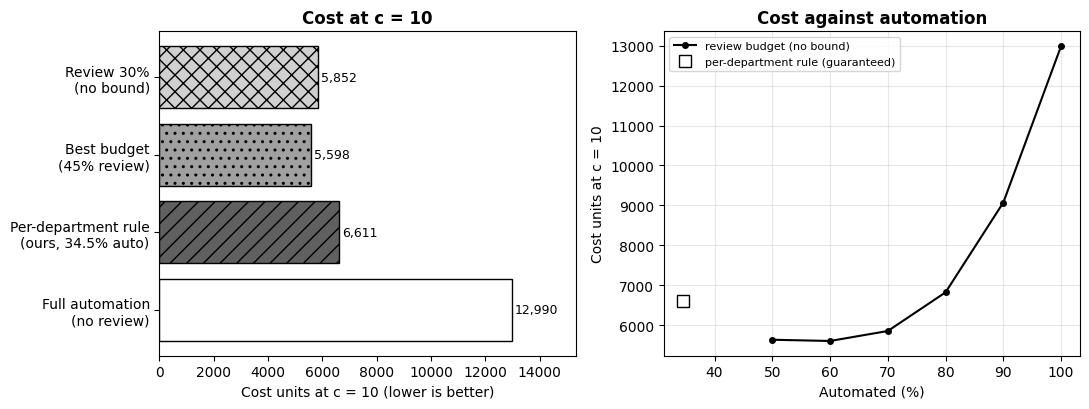

Reviewer-accuracy caveat: the end-to-end accuracies in the cost table assume a perfect reviewer; see the reviewer sweep table.


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
PROJ = '/content/drive/MyDrive/complaint_routing'
b = pd.read_csv(f'{PROJ}/table_budget_and_cost.csv')
head = b.iloc[0]
bud = b.iloc[1:].copy()
bud['budget'] = bud['rule'].str.extract(r'(\d+)%').astype(float)
bars = {
    'Full automation\n(no review)': 12990,
    'Per-department rule\n(ours, 34.5% auto)': head['cost_c10'],
    'Best budget\n(45% review)': 5598,
    'Review 30%\n(no bound)': float(bud.loc[bud['budget'] == 30, 'cost_c10'].iloc[0]),
}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
names = list(bars); vals = list(bars.values())
ax[0].barh(names, vals, color=['#ffffff', '#606060', '#a0a0a0', '#d0d0d0'], edgecolor='black', hatch=['', '//', '..', 'xx'])
for i, v in enumerate(vals): ax[0].text(v + 100, i, f'{v:,.0f}', va='center', fontsize=9)
ax[0].set_xlabel('Cost units at c = 10 (lower is better)'); ax[0].set_title('Cost at c = 10', fontweight='bold')
ax[0].set_xlim(0, max(vals) * 1.18)
ax[1].plot(bud['automated_%'], bud['cost_c10'], 'k-o', ms=4, label='review budget (no bound)')
ax[1].plot(head['automated_%'], head['cost_c10'], 'ks', ms=9, mfc='white', label='per-department rule (guaranteed)')
ax[1].set_xlabel('Automated (%)'); ax[1].set_ylabel('Cost units at c = 10'); ax[1].grid(alpha=.3)
ax[1].set_title('Cost against automation', fontweight='bold'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{PROJ}/fig_cost.png', dpi=200); plt.show()
print("Reviewer-accuracy caveat: the end-to-end accuracies in the cost table assume a perfect reviewer; see the reviewer sweep table.")

In [ ]:
import glob, os
from PIL import Image
PROJ = '/content/drive/MyDrive/complaint_routing'
files = sorted(glob.glob(f'{PROJ}/fig*.png'))
for f in files:
    if f.endswith('_gray.png'): continue
    im = Image.open(f).convert('L')
    out = f.replace('.png', '_gray.png'); im.save(out, dpi=(200, 200))
    print('grayscale copy:', os.path.basename(out))
print(len(files), 'figures converted')

grayscale copy: fig0_headline_gray.png
grayscale copy: fig1_risk_coverage_gray.png
grayscale copy: fig2_confusion_gray.png
grayscale copy: fig3_reliability_gray.png
grayscale copy: fig_confusion_gray.png
grayscale copy: fig_cost_gray.png
grayscale copy: fig_data_gray.png
grayscale copy: fig_pool_mix_gray.png
grayscale copy: fig_reliability_gray.png
grayscale copy: fig_risk_coverage_gray.png
grayscale copy: fig_robustness_gray.png
grayscale copy: fig_temperature_gray.png
grayscale copy: fig_threshold_sweep_gray.png
grayscale copy: fig_train_loss_gray.png
grayscale copy: fig_weights_gray.png
30 figures converted


In [ ]:
import numpy as np, pandas as pd

PROJ = '/content/drive/MyDrive/complaint_routing'
B_CI = 1000
rng_ci = np.random.default_rng(2024)
N_t = len(yte)

def ci_summary(auto, wrong, reps=B_CI):
    """Bootstrap the test set: returns mean and 95% interval for automated %, misrouted-among-automated %, overall %."""
    a_s, m_s, o_s = [], [], []
    for _ in range(reps):
        i = rng_ci.integers(0, N_t, N_t)
        a = auto[i]; w = wrong[i]
        a_s.append(a.mean() * 100)
        m_s.append(w[a].mean() * 100 if a.any() else np.nan)
        o_s.append((w & a).mean() * 100)
    out = {}
    for name, v in [('auto', a_s), ('mis', m_s), ('ovr', o_s)]:
        v = np.asarray(v, float)
        out[name] = f"{np.nanmean(v):.2f} [{np.nanpercentile(v, 2.5):.2f}, {np.nanpercentile(v, 97.5):.2f}]"
    return out

# ---- 1. methods table with intervals
method_thr = [
    ('Fixed cutoff 0.85', np.full(N_t, 0.85)),
    ('Empirical cutoff (no margin)', np.full(N_t, t_emp)),
    ('RCPS, global', np.full(N_t, t_global)),
    ('LTT, global (simplified, Bonferroni)', np.full(N_t, t_ltt)),
    ('RCPS, per-department (headline)', t_dept[pred_t]),
    ('RCPS, per-department, uncorrected (comparison only)', t_dept_uncorr[pred_t]),
    ('RCPS, per-department, delta/8', t_dept_d8[pred_t]),
]
rows = []
for name, thr in method_thr:
    auto = conf_t >= thr
    s = ci_summary(auto, wrong_t)
    rows.append({'method': name, 'automated_% [95% CI]': s['auto'],
                 'misrouted_among_automated_% [95% CI]': s['mis'], 'misrouted_overall_% [95% CI]': s['ovr']})
ci_methods = pd.DataFrame(rows); ci_methods.to_csv(f'{PROJ}/table_ci_methods.csv', index=False)
print(ci_methods.to_string(index=False))

# ---- 2. target comparison with intervals (5%, 7%, 10%)
rows = []
for a_t in [0.05, 0.07, 0.10]:
    td = np.array([pick_rcps(confB[predB == k], wrongB[predB == k], alpha=a_t, delta=DELTA / N_GRID,
                             min_n=MIN_N_DEPT)[0] for k in range(K)])
    auto = conf_t >= td[pred_t]
    s = ci_summary(auto, wrong_t)
    rows.append({'target': f'{a_t*100:.0f}%', 'automated_% [95% CI]': s['auto'],
                 'misrouted_among_automated_% [95% CI]': s['mis'], 'misrouted_overall_% [95% CI]': s['ovr']})
ci_targets = pd.DataFrame(rows); ci_targets.to_csv(f'{PROJ}/table_ci_targets.csv', index=False)
print(ci_targets.to_string(index=False))

# ---- 3. cost with intervals (headline rule and 30% review budget, c = 10)
order_c = np.argsort(conf_t, kind='stable')
a30 = np.ones(N_t, bool); a30[order_c[: int(round(0.30 * N_t))]] = False
cost_rows = []
for name, auto in [('Per-department rule (headline)', conf_t >= t_dept[pred_t]),
                   ('Review 30% (no bound)', a30)]:
    costs = []
    for _ in range(B_CI):
        i = rng_ci.integers(0, N_t, N_t)
        a = auto[i]; w = wrong_t[i]
        costs.append((~a).sum() + 10 * (w & a).sum())
    costs = np.asarray(costs, float)
    cost_rows.append({'rule': name, 'cost at c=10 [95% CI]':
                      f"{costs.mean():,.0f} [{np.percentile(costs, 2.5):,.0f}, {np.percentile(costs, 97.5):,.0f}]"})
ci_cost = pd.DataFrame(cost_rows); ci_cost.to_csv(f'{PROJ}/table_ci_cost.csv', index=False)
print(ci_cost.to_string(index=False))

# ---- 4. ranking ablation with intervals on AURC
score_sets = {
    'DistilBERT confidence only': (Pte.max(1), pred_t),
    'SVM confidence only': (Ste.max(1), Ste.argmax(1)),
    'Average of both probabilities': (((Pte + Ste) / 2).max(1), ((Pte + Ste) / 2).argmax(1)),
    'Full fused score (5 signals)': (fused, pred_t),
}
rows = []
for name, (score, pr) in score_sets.items():
    w = pr != yte
    vals = []
    for _ in range(B_CI):
        i = rng_ci.integers(0, N_t, N_t)
        vals.append(aurc(score[i], w[i]))
    vals = np.asarray(vals)
    rows.append({'scoring': name, 'AURC [95% CI]':
                 f"{aurc(score, w):.4f} [{np.percentile(vals, 2.5):.4f}, {np.percentile(vals, 97.5):.4f}]"})
ci_abl = pd.DataFrame(rows); ci_abl.to_csv(f'{PROJ}/table_ci_ablation.csv', index=False)
print(ci_abl.to_string(index=False))
print("Intervals reflect test-set sampling only. Calibration-split variability is in Section 7.")

                                             method automated_% [95% CI] misrouted_among_automated_% [95% CI] misrouted_overall_% [95% CI]
                                  Fixed cutoff 0.85 71.76 [70.81, 72.66]                    5.33 [4.82, 5.87]            3.83 [3.47, 4.21]
                       Empirical cutoff (no margin) 68.37 [67.44, 69.28]                    4.77 [4.25, 5.32]            3.26 [2.91, 3.64]
                                       RCPS, global 65.01 [64.00, 65.92]                    4.43 [3.89, 4.94]            2.88 [2.54, 3.22]
               LTT, global (simplified, Bonferroni) 60.62 [59.63, 61.67]                    3.85 [3.33, 4.36]            2.33 [2.00, 2.65]
                    RCPS, per-department (headline) 34.52 [33.58, 35.55]                    2.54 [1.97, 3.09]            0.88 [0.67, 1.07]
RCPS, per-department, uncorrected (comparison only) 58.33 [57.16, 59.35]                    4.29 [3.75, 4.85]            2.50 [2.19, 2.83]
                      RCPS,

In [ ]:
import numpy as np, pandas as pd
from scipy.optimize import minimize_scalar
from sklearn.model_selection import train_test_split

PROJ = '/content/drive/MyDrive/complaint_routing'
R = 20
VIOL = ALPHA * 100

def crc_lambda(cB_, wB_, alpha, n_cal):
    feas = [lam for lam in GRID if (n_cal / (n_cal + 1)) * np.mean((cB_ >= lam) & wB_) + 1 / (n_cal + 1) <= alpha]
    return min(feas) if feas else np.inf

rec = {'Global RCPS': [], 'LTT, global (Bonferroni)': [], 'Conformal risk control (overall target)': [],
       'Per-department RCPS (delta/200)': [], 'Per-department, uncorrected': [], 'Per-department, delta/8': []}
for r in range(R):
    iA, iB_r = train_test_split(np.arange(len(ycal)), test_size=0.5, stratify=ycal, random_state=100 + r)
    iA1_r, _ = train_test_split(iA, test_size=0.5, stratify=ycal[iA], random_state=200 + r)
    Tr = minimize_scalar(lambda t: nll(t, Lcal[iA1_r], ycal[iA1_r]), bounds=(0.5, 5.0), method='bounded').x
    Pc = softmax(Lcal[iB_r] / Tr); Pt = softmax(Lte / Tr)
    cB, pB, wB = Pc.max(1), Pc.argmax(1), Pc.argmax(1) != ycal[iB_r]
    cT, pT = Pt.max(1), Pt.argmax(1); wT = pT != yte

    tg, _ = pick_rcps(cB, wB, min_n=MIN_N_GLOBAL)
    a = cT >= tg
    rec['Global RCPS'].append(bool(a.any() and wT[a].mean() * 100 > VIOL))

    tl, _ = pick_ltt(cB, wB)
    a = cT >= tl
    rec['LTT, global (Bonferroni)'].append(bool(a.any() and wT[a].mean() * 100 > VIOL))

    lam = crc_lambda(cB, wB, ALPHA, len(iB_r))
    a = cT >= lam
    rec['Conformal risk control (overall target)'].append(bool((wT & a).mean() * 100 > VIOL))

    for label, delta in [('Per-department RCPS (delta/200)', DELTA / N_GRID),
                         ('Per-department, uncorrected', DELTA),
                         ('Per-department, delta/8', DELTA / K)]:
        td = np.array([pick_rcps(cB[pB == k], wB[pB == k], delta=delta, min_n=MIN_N_DEPT)[0] for k in range(K)])
        for k in range(K):
            a = (pT == k) & (cT >= td[k])
            if a.any():
                rec[label].append(bool(wT[a].mean() * 100 > VIOL))

rows = []
for name, v in rec.items():
    v = np.asarray(v)
    unit = 'of splits' if name.startswith(('Global', 'LTT', 'Conformal')) else f'of (split, department) pairs, from {len(v)}'
    rows.append({'method': name, 'target': ('overall misrouting <= 5%' if name.startswith('Conformal')
                                            else 'misrouted among automated <= 5%'),
                 'violation rate (target <= 10%)': f"{v.mean()*100:.1f}% {unit}",
                 'meets 10% limit?': 'yes' if v.mean() <= 0.10 else 'no'})
viol = pd.DataFrame(rows); viol.to_csv(f'{PROJ}/table_violation_rates.csv', index=False)
print(viol.to_string(index=False))
print("Fixed 0.85 and the empirical cutoff carry no guarantee, so they have no violation rate.")

                                 method                          target               violation rate (target <= 10%) meets 10% limit?
                            Global RCPS misrouted among automated <= 5%                               5.0% of splits              yes
               LTT, global (Bonferroni) misrouted among automated <= 5%                               0.0% of splits              yes
Conformal risk control (overall target)        overall misrouting <= 5%                              45.0% of splits               no
        Per-department RCPS (delta/200) misrouted among automated <= 5%   0.0% of (split, department) pairs, from 58              yes
            Per-department, uncorrected misrouted among automated <= 5% 20.9% of (split, department) pairs, from 129               no
                Per-department, delta/8 misrouted among automated <= 5%   5.3% of (split, department) pairs, from 95              yes
Fixed 0.85 and the empirical cutoff carry no guarantee, so the

In [ ]:
import numpy as np, pandas as pd

PROJ = '/content/drive/MyDrive/complaint_routing'
REPS = 1000
rng_g = np.random.default_rng(777)

def fmt(point, v):
    v = np.asarray(v, float)
    if not np.isfinite(point):
        return 'n/a'
    return f"{point:.2f} [{np.nanpercentile(v, 2.5):.2f}, {np.nanpercentile(v, 97.5):.2f}]"

def overall_point(pred, conf, wrong, thr):
    a = conf >= thr[pred]
    auto = a.mean() * 100
    mis = wrong[a].mean() * 100 if a.any() else np.nan
    return auto, mis, (wrong & a).mean() * 100

def overall_ci(pred, conf, wrong, thr):
    n = len(pred); out = np.empty((REPS, 3))
    for r in range(REPS):
        i = rng_g.integers(0, n, n)
        p, c, w = pred[i], conf[i], wrong[i]
        a = c >= thr[p]
        out[r] = [a.mean() * 100, w[a].mean() * 100 if a.any() else np.nan, (w & a).mean() * 100]
    return out

def dept_point(pred, conf, wrong, thr):
    a = conf >= thr[pred]
    pa = np.array([(a & (pred == k)).sum() / max((pred == k).sum(), 1) * 100 for k in range(K)])
    pm = np.array([wrong[a & (pred == k)].mean() * 100 if (a & (pred == k)).any() else np.nan for k in range(K)])
    return pa, pm

def dept_ci(pred, conf, wrong, thr):
    n = len(pred); A = np.full((REPS, K), np.nan); M = np.full((REPS, K), np.nan)
    for r in range(REPS):
        i = rng_g.integers(0, n, n)
        p, c, w = pred[i], conf[i], wrong[i]
        a = c >= thr[p]
        for k in range(K):
            ma = (p == k) & a
            A[r, k] = ma.sum() / max((p == k).sum(), 1) * 100
            M[r, k] = w[ma].mean() * 100 if ma.any() else np.nan
    return A, M

def dept_table(pred, conf, wrong, thr, title, fname):
    pa, pm = dept_point(pred, conf, wrong, thr)
    A, M = dept_ci(pred, conf, wrong, thr)
    rows = []
    for k in range(K):
        cut = round(float(thr[k]), 4) if np.isfinite(thr[k]) else 'defer all'
        rows.append({'department': LABELS[k], 'cutoff': cut,
                     'automated_% [95% CI]': fmt(pa[k], A[:, k]),
                     'misrouted_among_automated_% [95% CI]': fmt(pm[k], M[:, k])})
    t = pd.DataFrame(rows); t.to_csv(f'{PROJ}/{fname}', index=False)
    print(title); print(t.to_string(index=False)); print()
    return t

# ---- A. per-department tables with intervals
dept_table(pred_t, conf_t, wrong_t, t_dept, 'Headline per-department rule, balanced test set', 'table_ci_dept_headline.csv')
dept_table(pred_p, conf_p, wrong_p, t_dept, 'Natural mix, frozen cutoffs', 'table_ci_pool_frozen.csv')
dept_table(pred_p[iB_p], conf_p[iB_p], wrong_p[iB_p], t_pool, 'Natural mix, recalibrated (half B)', 'table_ci_pool_recal.csv')
dept_table(pred_k[late], conf_k[late], wrong_k[late], t_dept, 'Latest 15% of pool, frozen cutoffs', 'table_ci_temporal.csv')

# ---- B. review budget table with intervals
rows = []
for b in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    kk = int(round(b * N))
    def mask(c):
        if kk == 0: return np.ones(len(c), bool)
        return c >= np.sort(c)[kk]
    a = mask(conf_t)
    auto = a.mean() * 100
    mis = wrong_t[a].mean() * 100 if a.any() else np.nan
    cost = (~a).sum() + 10 * (wrong_t & a).sum()
    boot = np.empty((REPS, 3))
    for r in range(REPS):
        i = rng_g.integers(0, N, N)
        c, w = conf_t[i], wrong_t[i]
        ai = mask(c)
        boot[r] = [ai.mean() * 100, w[ai].mean() * 100 if ai.any() else np.nan, (~ai).sum() + 10 * (w & ai).sum()]
    rows.append({'review budget': f'{b*100:.0f}%',
                 'automated_% [95% CI]': fmt(auto, boot[:, 0]),
                 'misrouted_among_automated_% [95% CI]': fmt(mis, boot[:, 1]),
                 'cost at c=10 [95% CI]': fmt(cost, boot[:, 2])})
bud_ci = pd.DataFrame(rows); bud_ci.to_csv(f'{PROJ}/table_ci_budget.csv', index=False)
print("Review budget baseline (no bound)"); print(bud_ci.to_string(index=False)); print()

# ---- C. reviewer accuracy sweep at 30% budget, with intervals
kk = int(round(0.3 * N))
thr30 = np.sort(conf_t)[kk]
a30 = conf_t >= thr30
rows = []
for rr in [1.0, 0.9, 0.85, 0.75, 0.6]:
    point = ((~wrong_t & a30).sum() + rr * (~a30).sum()) / N * 100
    boot = []
    for _ in range(REPS):
        i = rng_g.integers(0, N, N)
        w, c = wrong_t[i], conf_t[i]
        ai = c >= thr30
        boot.append(((~w & ai).sum() + rr * (~ai).sum()) / N * 100)
    rows.append({'reviewer accuracy %': round(rr * 100, 1), 'end-to-end accuracy % [95% CI]': fmt(point, np.array(boot))})
sweep_ci = pd.DataFrame(rows); sweep_ci.to_csv(f'{PROJ}/table_ci_reviewer_sweep.csv', index=False)
print("Reviewer accuracy sweep, 30% budget"); print(sweep_ci.to_string(index=False)); print()

# ---- D. conformal risk control with intervals (cutoff fixed from half B)
rows = []
for a_t in [0.01, 0.02, 0.05]:
    lam = crc_cutoff(a_t)
    if lam is None:
        rows.append({'target (overall misrouting)': f'{a_t*100:.0f}%', 'cutoff': 'none on grid'}); continue
    thr = np.array([lam])
    pred1 = np.zeros(N, int)
    auto_pt, mis_pt, ovr_pt = overall_point(pred1, conf_t, wrong_t, thr)
    boot = overall_ci(pred1, conf_t, wrong_t, thr)
    rows.append({'target (overall misrouting)': f'{a_t*100:.0f}%', 'cutoff': round(float(lam), 4),
                 'automated_% [95% CI]': fmt(auto_pt, boot[:, 0]),
                 'misrouted_overall_% [95% CI]': fmt(ovr_pt, boot[:, 2]),
                 'misrouted_among_automated_% [95% CI]': fmt(mis_pt, boot[:, 1])})
crc_ci = pd.DataFrame(rows); crc_ci.to_csv(f'{PROJ}/table_ci_crc.csv', index=False)
print("Conformal risk control"); print(crc_ci.to_string(index=False)); print()

# ---- E. per-class precision, recall and F1 with intervals (test set)
def prf(y, p):
    out = np.zeros((K, 3))
    for k in range(K):
        tp = ((p == k) & (y == k)).sum(); fp = ((p == k) & (y != k)).sum(); fn = ((p != k) & (y == k)).sum()
        pr = tp / max(tp + fp, 1); rc = tp / max(tp + fn, 1)
        out[k] = [pr, rc, 2 * pr * rc / max(pr + rc, 1e-12)]
    return out
pt = prf(yte, pred_t)
bs = np.empty((REPS, K, 3))
for r in range(REPS):
    i = rng_g.integers(0, N, N)
    bs[r] = prf(yte[i], pred_t[i])
rows = []
for k in range(K):
    rows.append({'department': LABELS[k],
                 'precision [95% CI]': fmt(pt[k, 0], bs[:, k, 0]),
                 'recall [95% CI]': fmt(pt[k, 1], bs[:, k, 1]),
                 'F1 [95% CI]': fmt(pt[k, 2], bs[:, k, 2])})
pc_ci = pd.DataFrame(rows); pc_ci.to_csv(f'{PROJ}/table_ci_per_class.csv', index=False)
print("Per-class DistilBERT on test"); print(pc_ci.to_string(index=False)); print()

# ---- F. baselines with intervals (DistilBERT, SVM, and BERT-base if it was run)
def rule_thr(Pc_):
    pB_ = Pc_[idxB].argmax(1); cB_ = Pc_[idxB].max(1); wB_ = pB_ != ycal[idxB]
    return np.array([pick_rcps(cB_[pB_ == k], wB_[pB_ == k], delta=DELTA / N_GRID, min_n=MIN_N_DEPT)[0] for k in range(K)])
models = [('DistilBERT (main model)', Pte, t_dept), ('TF-IDF + SVM (baseline)', Ste, rule_thr(Scal))]
if 'Pte_b' in globals() and 'Pcal_b' in globals():
    models.insert(1, ('BERT-base (stronger baseline)', Pte_b, rule_thr(Pcal_b)))
rows = []
for name, Pt_, thr in models:
    pred = Pt_.argmax(1); conf = Pt_.max(1); wrong = pred != yte
    auto_pt, mis_pt, ovr_pt = overall_point(pred, conf, wrong, thr)
    boot = overall_ci(pred, conf, wrong, thr)
    rows.append({'model': name, 'automated_% [95% CI]': fmt(auto_pt, boot[:, 0]),
                 'misrouted_among_automated_% [95% CI]': fmt(mis_pt, boot[:, 1]),
                 'misrouted_overall_% [95% CI]': fmt(ovr_pt, boot[:, 2])})
base_ci = pd.DataFrame(rows); base_ci.to_csv(f'{PROJ}/table_ci_baselines.csv', index=False)
print("Baselines under the same rule"); print(base_ci.to_string(index=False))
print("\nIntervals reflect resampling of the test set (cutoffs fixed). Calibration-split variability is in Section 7.")

Headline per-department rule, balanced test set
           department    cutoff automated_% [95% CI] misrouted_among_automated_% [95% CI]
         Bank Account      0.94 52.54 [49.67, 55.29]                    3.01 [1.81, 4.39]
          Credit Card defer all    0.00 [0.00, 0.00]                                  n/a
     Credit Reporting    0.9475 56.92 [53.76, 59.66]                    1.69 [0.73, 2.67]
      Debt Collection defer all    0.00 [0.00, 0.00]                                  n/a
       Money Transfer defer all    0.00 [0.00, 0.00]                                  n/a
             Mortgage    0.9475 60.97 [58.24, 63.85]                    3.15 [1.91, 4.52]
         Student Loan    0.8775 86.70 [84.78, 88.51]                    2.35 [1.51, 3.23]
Vehicle/Personal Loan defer all    0.00 [0.00, 0.00]                                  n/a

Natural mix, frozen cutoffs
           department    cutoff automated_% [95% CI] misrouted_among_automated_% [95% CI]
         Bank Account  